# Базовые варианты: новости → «бак» Орнштейна–Уленбека → рынок

Эта тетрадка — **простой, подробный и проверяемый** вариант всей цепочки курсовой на уже собранном датасете.
Она написана так, чтобы её можно было читать сверху вниз как текст: перед каждым блоком кода сказано, *зачем* он нужен,
после — *как читать* результат и *что из него следует* для следующего шага.

### Карта тетрадки

| № | Пункт плана | Что делаем здесь |
|---|---|---|
| 1 | Датасет новостей и рынка с одной частотой и периодом | берём готовые файлы, выбираем однородный период, раскладываем новости по торговым дням |
| 2 | Эмбеддинг новостей $\varepsilon_t$ | несколько способов превратить новости дня в числа, очистка от тренда |
| 3 | Динамика OU: $x_{t+\Delta t}=A\,x_t+\varepsilon_t$, $A$ сжимающая | «бак», в который доливаются новости и который постепенно забывает |
| 4 | Наблюдение $p_t=\langle g,x_t\rangle$ и **алгоритмы обучения** | что наблюдаем вместо цены; как именно находятся $g$ и $A$ |
| 5 | Проверка качества | метрики, синтетика, бейзлайны, главная таблица, плацебо, по годам, форма памяти |
| 6 | Дополнительные эксперименты | календарь, задержка новостей, размерность, темы или рубрики, спокойный/нервный рынок, другие цели, финансовые или все новости, ловушка подглядывания |
| 7 | Итоги | сводная таблица и как её читать |

### Главная идея модели в одном абзаце

Каждое утро выходят новости. Мы превращаем их в короткий вектор чисел $\varepsilon_t$ («удар» новостей).
Удары накапливаются в скрытом состоянии $x_t$ — как вода в баке с маленькой дыркой: новая вода доливается,
старая понемногу вытекает (рынок забывает старые новости). Рынок «читает» состояние бака линейно:
наблюдаемая величина $\approx\langle g,x_t\rangle$. Обучение — это поиск скорости вытекания ($A$) и весов чтения ($g$).

### Главный принцип — честное время

Прогноз для торгового дня $t$ может опираться только на то, что было известно **до открытия биржи**
(9:30 по Нью-Йорку) в день $t$. Поэтому:

* новости берём только опубликованные **до 9:30** дня $t$;
* предсказываем то, что происходит **после открытия** — размах цены за торговую сессию.

**Главный вопрос тетрадки:** *добавляют ли новости что-то к тому, что и так известно из истории рынка?*
Ответ «нет» — тоже полноценный научный результат, если он честно проверен.

### Словарик

| термин | простыми словами |
|---|---|
| **эмбеддинг** | способ записать текст несколькими числами так, чтобы похожие тексты давали похожие числа |
| **train / val / test** | три непересекающихся куска времени: на первом учимся, на втором выбираем настройки, на третьем один раз честно проверяем |
| **переобучение** | модель запомнила шум обучающих данных и плохо работает на новых |
| **ridge-регрессия** | линейная регрессия со штрафом за большие коэффициенты; штраф защищает от переобучения |
| **гиперпараметр** | настройка, которую не находит сама регрессия (у нас: период полураспада $h$ и сила штрафа $\alpha$) |
| **MSE** | средний квадрат ошибки прогноза — чем меньше, тем лучше |
| **$R^2$** | доля разброса, которую объясняет модель по сравнению с прогнозом «всегда среднее»: 0 — не лучше среднего, 1 — идеально, < 0 — хуже среднего |
| **IC** | ранговая корреляция прогноза и факта: угадывает ли модель, какие дни будут «больше», а какие «меньше» |
| **бейзлайн / база** | простая модель без новостей, с которой сравниваем |
| **p-value** | вероятность получить такой же или лучший результат случайно, если на самом деле эффекта нет; маленькое — эффект вряд ли случаен |
| **плацебо-тест** | тот же расчёт, но с намеренно сломанной связью (новости не того дня) — показывает, какой «эффект» бывает от случайности |
| **поправка Холма** | поправка p-value, когда проверок много: чем больше попыток, тем строже требование к каждой |

## 0.1. Настройки

Все параметры, которые имеет смысл менять, собраны в одной ячейке. Остальной код от них зависит, но сам их не меняет.
Если хочется попробовать другой инструмент или другой период — меняйте здесь и перезапускайте всё.

**Воспроизводимость.** Случайность в тетрадке есть только в двух местах — в синтетических проверках и в сдвигах
плацебо. Оба берут собственные генераторы `make_rng(...)`, построенные из `SEED` и номера шага. Сжатие признаков
(SVD для TF-IDF, PCA для SBERT) намеренно сделано **точным**: у библиотек по умолчанию стоит быстрый
рандомизированный алгоритм, и тогда даже сами темы TF-IDF немного менялись бы от сида к сиду. Поэтому:

* при одном и том же `SEED` и тех же данных тетрадка даёт одни и те же числа при каждом запуске;
* любую ячейку можно перезапустить отдельно — результат не изменится (у каждого шага свой генератор,
  он не «продолжает» общий);
* смена `SEED` меняет только синтетику и плацебо, а эмбеддинги, подбор настроек и все тестовые метрики остаются
  прежними. Это полезно, чтобы убедиться, что p-value плацебо не держится на одном удачном сиде.

Остальное (TF-IDF, словарь, ridge, подбор по сетке, L-BFGS) случайности не содержит. SBERT на CPU тоже детерминирован,
а после первого запуска его векторы читаются из кэша.

In [1]:
import hashlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import norm, spearmanr
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

from scripts import config as C
from scripts.align import session_open_utc
from scripts.news import article_text

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "figure.figsize": (11, 3.6)})

# ---------- что и на каком периоде ----------
TICKER = "SPY"                  # основной инструмент: ETF на S&P 500 (у него настоящие цены открытия)
START, END = "2008-01-01", "2023-04-30"
TRAIN_END = "2016-12-31"        # обучение:  2008–2016 (первый год — «разогрев» признаков)
VAL_END = "2019-12-31"          # валидация: 2017–2019 — здесь выбираем настройки
                                # тест:      2020 → END — смотрим один раз, в самом конце
# ---------- модель ----------
HALF_LIVES = [0, 1, 2, 3, 5, 7, 14, 30, 60]   # кандидаты периода полураспада памяти, календарные дни (0 = памяти нет)
ALPHAS = [1, 10, 100, 1000]                   # кандидаты силы ridge-штрафа
D_TFIDF = 8                                   # размерность ε_t для TF-IDF / SBERT
Z_WINDOW = 252                                # окно «очистки» признаков (≈ 1 год торговых дней)
WARMUP = 252                                  # первые дни не оцениваем: окна признаков ещё не заполнены
USE_SBERT = True                              # SBERT (нужен пакет sentence-transformers; без него шаг пропускается)
SBERT_ALL_NEWS = True                       # SBERT и для нефинансовых статей в эксперименте 6.7
                                              # (статей примерно втрое больше: первый запуск на CPU — долго, потом кэш)
# ---------- проверки ----------
N_PLACEBO = 200
MIN_GAIN = 0.5                                # «практически заметный» прирост к базе, % MSE
OTHER_TICKERS = ["SPY", "QQQ", "XLK", "XLF", "XLE"]
SEED = 0                                      # единый сид: от него зависят ВСЕ случайные шаги тетрадки

def make_rng(*keys):
    # отдельный генератор для каждого случайного шага: результат не зависит от порядка и числа перезапусков ячеек
    return np.random.default_rng([SEED, *keys])

---
# 1. Данные: новости и рынок на одних торговых днях

**Зачем этот раздел.** Модель связывает два разных мира — тексты и цены. Чтобы связь была честной, оба должны
жить на одной временной шкале с одним шагом. Наш шаг — **один торговый день**.

Датасет уже собран (`dataset.ipynb`, `scripts/`). Берём из него два файла:

* `news_articles.parquet` — статьи New York Times со временем публикации и флагом `is_finance`
  (статья о бизнесе, рынках или экономике);
* `market_prices.parquet` — дневные цены: открытие, максимум, минимум, закрытие.

**Почему период 2008 → апрель 2023.** Датасет длиннее, но не везде однороден:

* примерно до 2007 года у статей указана только дата, без времени публикации, — нельзя честно отделить
  «до открытия» от «во время торгов»;
* с мая 2023 у статей нет рубрик, и флаг `is_finance` угадан классификатором, а не взят из метаданных.

В выбранном окне источник один и тот же, время публикации есть, рубрики настоящие. Лучше 15 однородных лет,
чем 35 лет, в которых смысл данных меняется по ходу.

In [2]:
for key in ("news", "prices"):
    if not C.PROCESSED_FILES[key].exists():
        raise FileNotFoundError(f"нет {C.PROCESSED_FILES[key]} — сначала соберите датасет (dataset.ipynb)")

prices = pd.read_parquet(C.PROCESSED_FILES["prices"])
prices["date"] = pd.to_datetime(prices["date"])

NEWS_COLS = ["pub_time_utc", "trading_date", "is_finance", "flag_source", "section",
             "headline", "abstract", "lead_paragraph"]
try:   # читаем только нужный период — файл большой
    news = pd.read_parquet(C.PROCESSED_FILES["news"], columns=NEWS_COLS,
                           filters=[("trading_date", ">=", pd.Timestamp(START))])
except Exception:
    news = pd.read_parquet(C.PROCESSED_FILES["news"], columns=NEWS_COLS)
news["trading_date"] = pd.to_datetime(news["trading_date"])
news = news[news["trading_date"] >= START]

# конец периода: последний день, где is_finance взят из метаданных, а не угадан классификатором
end = pd.Timestamp(END)
guessed = news.loc[news["flag_source"] == "text_model", "trading_date"]
if len(guessed):
    end = min(end, guessed.min() - pd.Timedelta(days=1))
print(f"период: {START} → {end.date()}")

период: 2008-01-01 → 2023-04-30


### 1.1. Торговый календарь и цены

Торговые дни берём из самого инструмента: день есть в данных — значит, биржа работала.
Между пятницей и понедельником проходит 3 календарных дня, а вокруг праздников — 2 или 4. Эти паузы
(`gap_days`) понадобятся в разделе 3: за выходные «бак» должен забыть больше, чем за одну ночь.

Цены корректируем на дивиденды (множитель `adj_close / close`): в день выплаты дивиденда цена ETF падает на его
размер, и без поправки это выглядело бы как настоящее движение рынка.

Затем делим время на три куска. **Важно, что деление по времени, а не случайное:** в финансах будущее не должно
подсказывать прошлому, а соседние дни похожи друг на друга — случайное перемешивание дало бы слишком оптимистичный результат.

In [3]:
def ohlc(ticker):
    # дневные цены с поправкой на дивиденды и сплиты
    p = prices[prices["ticker"] == ticker].set_index("date").sort_index()
    f = p["adj_close"] / p["close"]
    return pd.DataFrame({"open": p["open"] * f, "high": p["high"] * f,
                         "low": p["low"] * f, "close": p["adj_close"]})

dates = ohlc(TICKER).loc[START:end].index                           # торговые дни
gap_days = dates.to_series().diff().dt.days.fillna(1).to_numpy()   # календарных дней с прошлой сессии

masks = {"train": np.asarray(dates <= TRAIN_END),
         "val":   np.asarray((dates > TRAIN_END) & (dates <= VAL_END)),
         "test":  np.asarray(dates > VAL_END)}
for k, m in masks.items():
    print(f"{k:5s} {dates[m][0].date()} → {dates[m][-1].date()}   {m.sum()} дней")
print("пауза между сессиями (календарных дней → сколько раз):", dict(pd.Series(gap_days).value_counts().sort_index()))

train 2008-01-02 → 2016-12-30   2267 дней
val   2017-01-03 → 2019-12-31   754 дней
test  2020-01-02 → 2023-04-28   837 дней
пауза между сессиями (календарных дней → сколько раз): {1.0: np.int64(3026), 2.0: np.int64(33), 3.0: np.int64(693), 4.0: np.int64(105), 5.0: np.int64(1)}


### 1.2. Новости, известные до открытия

Каждая статья в датасете уже привязана к торговому дню `trading_date`: это первый день, закрытие которого
наступило после публикации. Внутри этого окна отделяем то, что вышло **до 9:30** — только это и войдёт в $\varepsilon_t$.

```
закрытие t−1 (16:00)        открытие t (9:30)                 закрытие t (16:00)
      |------ новости до открытия ------|------------ торговая сессия t ------------|
                → ε_t                                 → что предсказываем
```

Новости, вышедшие во время сессии, часто *описывают* сам день («акции упали на…») — их брать нельзя.
В разделе 6.8 покажем, что будет, если нарушить это правило.

**Какие статьи берём.** В основной постановке — только **финансовые** (`is_finance`): бизнес-раздел, рыночные и
макроэкономические темы. Это примерно треть потока. Остальные рубрики (мир, политика, США, наука, здоровье…)
тоже загружаем, но используем только в эксперименте 6.7, где проверяем, не теряем ли мы с ними что-то важное.

In [4]:
open_utc = pd.Series(session_open_utc(dates).tz_convert("UTC").tz_localize(None), index=dates)

news = news[news["trading_date"].isin(dates)].copy()
pub = news["pub_time_utc"].dt.tz_convert("UTC").dt.tz_localize(None)
news["pre_open"] = (pub <= news["trading_date"].map(open_utc)).to_numpy()

pre_all = news[news["pre_open"]]          # утренние статьи ВСЕХ рубрик — только для эксперимента 6.7
news = news[news["is_finance"]]           # основная постановка: только финансовые статьи
pub = pub.loc[news.index]

pre = news[news["pre_open"]]
text_pre = article_text(pre).groupby(pre["trading_date"]).agg("\n".join).reindex(dates).fillna("")
n_pre = pre.groupby("trading_date").size().reindex(dates).fillna(0).to_numpy()
# весь день (до закрытия) — понадобится только для демонстрации ошибки в 6.8
text_day = article_text(news).groupby(news["trading_date"]).agg("\n".join).reindex(dates).fillna("")

print(f"финансовых статей: {len(news):,}, из них до открытия: {len(pre):,} ({len(pre) / len(news):.0%})")
print(f"утренних статей всех рубрик: {len(pre_all):,} — финансовые из них {len(pre) / len(pre_all):.0%}")
print("пример утренних заголовков:", dates[-1].date())
print("\n".join(text_pre.iloc[-1].split("\n")[:5]))

финансовых статей: 191,984, из них до открытия: 139,095 (72%)
утренних статей всех рубрик: 511,935 — финансовые из них 27%
пример утренних заголовков: 2023-04-28
Snap’s Sales Fall for First Time as a Public Company. As other tech companies returned to growth, Snap continued to struggle with advertising sales and lost money in the first quarter.
Amazon’s Growth Is Slow but Good Enough. The company, reporting a 9 percent revenue increase for the first quarter, is the latest Big Tech company to top Wall Street’s financial expectations.
Your Friday Briefing: Russia’s Crumbling Gas Exports. Also, President Yoon’s address to Congress and Australia’s shift on New Zealand.
Questions Swirl About NBCUniversal’s Future After C.E.O.’s Shocking Firing. Mike Cavanagh, now in charge of NBCUniversal, is meeting with talent including Lester Holt and Jimmy Fallon as he ponders next steps for the business.
The Real Debt Limit Fight Is Yet to Come. Speaker Kevin McCarthy squeezed a debt ceiling increase o

**Когда публикуются статьи?** Гистограмма часа публикации (по Нью-Йорку) показывает, какая доля потока успевает
до открытия, а какая выходит во время торгов. Пик в полночь — статьи, у которых указана только дата
(обычно это материалы утреннего печатного выпуска; они известны до открытия).

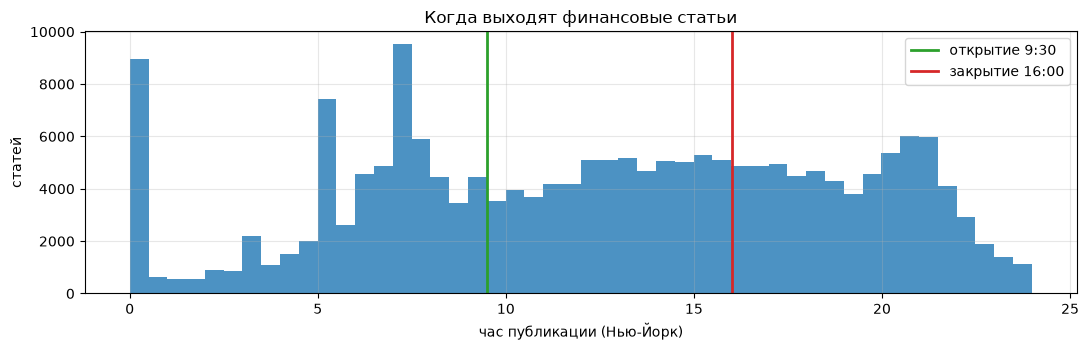

In [5]:
pub_ny = news["pub_time_utc"].dt.tz_convert("America/New_York")
hour = pub_ny.dt.hour + pub_ny.dt.minute / 60
fig, ax = plt.subplots()
ax.hist(hour, bins=48, color="C0", alpha=0.8)
ax.axvline(9.5, color="C2", lw=2, label="открытие 9:30")
ax.axvline(16, color="C3", lw=2, label="закрытие 16:00")
ax.set_xlabel("час публикации (Нью-Йорк)"); ax.set_ylabel("статей")
ax.set_title("Когда выходят финансовые статьи"); ax.legend()
plt.tight_layout(); plt.show()

### 1.3. Аудит: где данные могут обмануть

Прежде чем строить модель, смотрим, как менялся сам поток новостей. Медленные изменения источника
(сколько статей пишут, когда их публикуют) модель легко примет за «сигнал». Таблица по годам:

год,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
фин. статей в день,98.2,123.4,94.6,61.9,59.3,50.9,53.6,40.7,31.8,25.6,23.6,20.7,24.2,23.4,23.5,20.9
"из них до 9:30, %",81.8,77.1,75.2,68.4,65.8,68.4,68.8,67.8,66.7,66.9,67.8,72.5,74.0,70.0,69.1,72.9
"без времени публикации, %",26.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
дней без утренних новостей,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


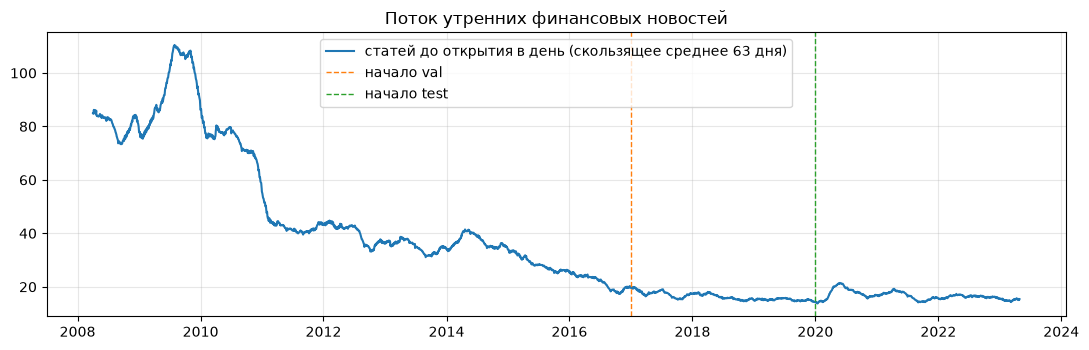

In [6]:
yr = news["trading_date"].dt.year
midnight = pub.dt.hour.isin([4, 5]) & (pub.dt.minute == 0) & (pub.dt.second == 0)   # полночь по Нью-Йорку = «только дата»
days_per_year = pd.Series(dates.year).value_counts().sort_index()
audit = pd.DataFrame({
    "фин. статей в день": news.groupby(yr).size() / days_per_year,
    "из них до 9:30, %": 100 * news.groupby(yr)["pre_open"].mean(),
    "без времени публикации, %": 100 * midnight.groupby(yr).mean(),
    "дней без утренних новостей": pd.Series(n_pre == 0, index=dates).groupby(dates.year).sum(),
}).round(1)
audit.index.name = "год"
display(audit.T)

fig, ax = plt.subplots()
ax.plot(dates, pd.Series(n_pre, index=dates).rolling(63).mean(), label="статей до открытия в день (скользящее среднее 63 дня)")
for m, c in (("val", "C1"), ("test", "C2")):
    ax.axvline(dates[masks[m]][0], color=c, ls="--", lw=1, label=f"начало {m}")
ax.set_title("Поток утренних финансовых новостей"); ax.legend()
plt.tight_layout(); plt.show()

**Что из этого следует.** Если в первом году заметная доля статей без времени публикации — это не страшно:
первый год (`WARMUP`) всё равно уходит на «разогрев» скользящих окон и в оценку не попадает.

Число статей в день заметно меняется год от года. Если подать в модель «сырые» величины,
она будет объяснять медленный тренд источника, а не дневную информацию. Поэтому в следующем разделе каждый
признак мы **очищаем по прошлому году** (скользящий z-score).

**Итог раздела 1:** у нас есть торговые дни, цены каждого дня и для каждого дня — текст новостей,
известных до открытия. Теперь превратим этот текст в числа.

---
# 2. Эмбеддинг новостей $\varepsilon_t$

**Зачем этот раздел.** Регрессия умеет работать только с числами. Нужно превратить текст новостей дня
в короткий вектор чисел — эмбеддинг. Короткий — потому что дней у нас всего несколько тысяч, и модель с сотнями
признаков просто запомнит шум.

Берём несколько способов, от простого к сложному:

| Название | Что считаем | Чисел в день | Что проверяет |
|---|---|---|---|
| `volume` | сколько статей вышло до открытия | 1 | «дело в количестве новостей, а не в их смысле?» |
| `lexicon` | доля «негативных», «позитивных» и «неопределённых» слов | 3 | простой смысл по словарю |
| `tfidf` | TF-IDF + сжатие (SVD) до 8 чисел | 8 | «о чём пишут», без заранее заданного словаря |
| `sbert` (по желанию) | нейросетевой эмбеддинг статей + PCA | 8 | понимание смысла предложений |

`volume` — **контрольный** вариант: если сложные эмбеддинги не лучше простого подсчёта статей,
значит, они ловят только «насколько шумный день», а не содержание.

Два правила для всех вариантов:

1. всё, что *обучается* (словарь TF-IDF, SVD, PCA), обучается **только на train** — иначе информация из будущего
   просочится в признаки через словарь;
2. каждый признак очищаем по прошлому году (раздел 2.5).

### 2.1. `volume` — сколько новостей

Самый простой признак: $\log(1+\text{число утренних статей}/\Delta t)$. Деление на $\Delta t$ нужно потому, что утро
понедельника собирает новости за все выходные — без поправки понедельник всегда казался бы «громким».

### 2.2. `lexicon` — словарь

Считаем, сколько слов из трёх списков (негатив, позитив, неопределённость) приходится на 1000 слов текста дня.
Это классический приём из финансового анализа текстов; настоящий словарь Loughran–McDonald длиннее,
здесь — короткая версия, чтобы было понятно, как это работает.

### 2.3. `tfidf` — о чём пишут

1. **TF-IDF.** Каждый день — это вектор длиной в словарь (десятки тысяч слов и пар слов). Вес слова тем больше,
   чем чаще оно встречается в этот день (TF) и чем *реже* — в другие дни (IDF):
   $$w_{\text{день},\text{слово}} = \log(1+\text{частота в день})\cdot\log\frac{\text{число дней}}{\text{число дней со словом}}.$$
   Слова, которые есть везде («company», «market»), почти ничего не весят.
2. **SVD (сжатие).** Векторы длиной 30 000 сжимаем до 8 чисел: SVD находит 8 направлений, вдоль которых
   дни различаются сильнее всего. Каждое направление — это «тема»: набор слов, которые часто встречаются вместе.
   Ниже печатаются слова с наибольшим весом в каждой теме — так можно понять, о чём она.

In [7]:
raw = {}
tr = masks["train"]

# --- 2.1 volume: статей на календарные сутки
raw["volume"] = pd.DataFrame({"log_n": np.log1p(n_pre / gap_days)}, index=dates)

# --- 2.2 lexicon: упрощённый финансовый словарь
NEG = """loss losses lose losing fall falls fell falling drop drops dropped decline declines declined plunge plunged
slump slumped crash crisis fear fears worry worries worried recession default defaults bankruptcy bankrupt layoffs cuts weak
weakness slowdown downturn selloff turmoil panic collapse fail failed failure threat threatens trouble troubled fraud
debt deficit unemployment""".split()
POS = """gain gains gained rise rises rose rising rally rallied surge surged jump jumped growth grow grew strong strength
recovery recover rebound boost improve improved improvement profit profits profitable optimism optimistic upbeat beat""".split()
UNC = """uncertain uncertainty unclear volatile volatility may might could possibly unsettled doubt doubts concern concerns
concerned unpredictable turbulence risk risks risky""".split()

def lexicon_features(texts):
    vocab = sorted(set(NEG + POS + UNC))
    col = {w: i for i, w in enumerate(vocab)}
    cnt = CountVectorizer(vocabulary=vocab, token_pattern=r"(?u)\b\w+\b").transform(texts)
    n_words = texts.str.split().str.len().fillna(0).clip(lower=1).to_numpy()
    rate = lambda ws: 1000 * np.asarray(cnt[:, [col[w] for w in set(ws)]].sum(axis=1)).ravel() / n_words
    return pd.DataFrame({"neg_rate": rate(NEG), "pos_rate": rate(POS), "unc_rate": rate(UNC)}, index=texts.index)

raw["lexicon"] = lexicon_features(text_pre)

# --- 2.3 tfidf + SVD (обучаем только на train)
def tfidf_features(d, texts=None):
    texts = text_pre if texts is None else texts
    vec = TfidfVectorizer(min_df=5, max_df=0.5, max_features=30_000, ngram_range=(1, 2),
                          sublinear_tf=True, stop_words="english").fit(texts[tr])
    Xs = vec.transform(texts)
    svd = TruncatedSVD(n_components=d, algorithm="arpack", random_state=SEED).fit(Xs[tr])   # точный SVD
    df = pd.DataFrame(svd.transform(Xs), index=dates, columns=[f"svd{i + 1}" for i in range(d)])
    return df, vec, svd

raw["tfidf"], vec, svd = tfidf_features(D_TFIDF)
terms = vec.get_feature_names_out()
TOPIC_WORDS = {f"svd{i + 1}": ", ".join(terms[np.argsort(c)[::-1][:6]]) for i, c in enumerate(svd.components_)}
print(f"словарь TF-IDF: {len(terms):,} слов и пар слов; 8 тем объясняют {svd.explained_variance_ratio_.sum():.1%} разброса")
print("О чём темы TF-IDF (слова с наибольшим весом):")
for k, v in TOPIC_WORDS.items():
    print(f"  {k}: {v}")

словарь TF-IDF: 30,000 слов и пар слов; 8 тем объясняют 2.3% разброса
О чём темы TF-IDF (слова с наибольшим весом):
  svd1: reported, profit, funds, credit, google, stake
  svd2: reported, reuters, street journal, reuters reported, journal, bloomberg news
  svd3: trump, morning agenda, agenda, donald trump, recent commercial, donald
  svd4: recent commercial, commercial real, transactions, estate transactions, real estate, estate
  svd5: trump, reuters reported, spill, reuters, donald trump, madoff
  svd6: trump, donald trump, donald, romney, estate transactions, commercial real
  svd7: trump, donald trump, donald, profit, thursday, clinton
  svd8: estate transactions, recent commercial, commercial real, transactions, real estate, estate


**Как читать.** Доля объяснённого разброса у TF-IDF обычно маленькая (несколько процентов) — это нормально:
тексты очень разнообразны, а 8 тем — грубое сжатие. Первая тема часто «общая» (самые частые слова),
следующие — более конкретные (нефть, ФРС, банки, технологии…).

**Осторожно: тема может оказаться рубрикой.** Газета регулярно публикует однотипные материалы — утренние дайджесты,
сводки сделок, перепечатки агентств. У них повторяются одни и те же слова, и SVD охотно делает из них «тему». Но такие
рубрики появляются и исчезают по редакционным причинам, а не из-за событий, и признак начинает отражать историю газеты,
а не новости. Если среди главных слов темы видны названия рубрик («morning agenda», «briefing», «reported»), —
это тот самый случай. В разделе 6.4 проверим, что будет, если такие рубрики убрать.

### 2.4. (Необязательно) SBERT

Нейросетевой эмбеддинг предложений: модель обучена так, что предложения с похожим смыслом получают близкие векторы
(даже если слова разные). Важная деталь: модель читает не больше ~256 токенов, поэтому склеивать все новости дня в одну
строку нельзя — она прочитает только первые несколько заголовков. Правильно — закодировать **каждую статью отдельно**
и усреднить векторы за день, потом сжать PCA (на train) до 8 чисел. Результат кэшируется на диск; ключ кэша зависит от
самих текстов, поэтому чужой кэш не подхватится.

In [8]:
SBERT_MODEL = None

def sbert_device():
    import torch
    return "cuda" if torch.cuda.is_available() else "cpu"

def sbert_encode(arts):
    # векторы статей; кэш на диске, ключ — хэш самих текстов
    global SBERT_MODEL
    key = hashlib.md5("\n".join(arts).encode("utf-8")).hexdigest()[:12]
    cache = C.EMBED_DIR / f"preopen_minilm_{key}.npz"
    if cache.exists():
        return np.load(cache)["emb"]
    import torch
    from sentence_transformers import SentenceTransformer
    device = sbert_device()
    if SBERT_MODEL is None:
        SBERT_MODEL = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
    elif str(SBERT_MODEL.device) != device:
        SBERT_MODEL = SBERT_MODEL.to(device)
    extra = f" ({torch.cuda.get_device_name(0)})" if device == "cuda" else ""
    print(f"SBERT encode: {len(arts):,} статей на {device}{extra}")
    bs = 256 if device == "cuda" else 64
    emb = SBERT_MODEL.encode(
        list(arts), batch_size=bs, show_progress_bar=True, normalize_embeddings=True, device=device,
    )
    C.EMBED_DIR.mkdir(parents=True, exist_ok=True)
    tmp = cache.with_name(cache.stem + ".tmp.npz")
    np.savez_compressed(tmp, emb=emb)
    tmp.replace(cache)                                    # атомарно: прерванный запуск не оставит битый кэш
    return emb

def sbert_daily(df, emb, d=D_TFIDF):
    # среднее векторов статей за день → PCA (обучен на train) до d чисел
    day = pd.DataFrame(emb).groupby(df["trading_date"].to_numpy()).mean().reindex(dates)
    day = day.fillna(day.loc[tr].mean())                      # дни без утренних новостей
    pca = PCA(n_components=d, svd_solver="full").fit(day.loc[tr])   # точный PCA, без случайности
    out = pd.DataFrame(pca.transform(day), index=dates, columns=[f"sbert{i + 1}" for i in range(d)])
    return out, pca.explained_variance_ratio_.sum()

SBERT_EMB = {}
if USE_SBERT:
    try:
        SBERT_EMB["fin"] = sbert_encode(article_text(pre).to_numpy())
        raw["sbert"], ev = sbert_daily(pre, SBERT_EMB["fin"])
        print(f"SBERT: {len(pre):,} статей, PCA объясняет {ev:.0%} дисперсии")
    except ImportError:
        print("sentence-transformers не установлен — SBERT пропускаем (pip install sentence-transformers)")
else:
    print("SBERT выключен (USE_SBERT = False)")

SBERT: 139,095 статей, PCA объясняет 26% дисперсии


### 2.5. Очистка: скользящий z-score по прошлому году

Для каждого признака и каждого дня $t$:

$$
\varepsilon_t=\frac{z_t-\text{среднее}(z_{t-252},\dots,z_{t-1})}{\text{ст.откл.}(z_{t-252},\dots,z_{t-1})},
$$

то есть «насколько сегодняшний день необычен по сравнению с прошлым годом». Это убирает медленные тренды источника
(раздел 1.3) и делает признаки сравнимыми по масштабу. В будущее не смотрим: окно заканчивается вчера.
Крайние значения обрезаем на ±5, чтобы один аномальный день не ломал регрессию.

Почему это особенно важно для OU: среднее состояние бака равно $\text{среднее}(\varepsilon)/(1-\lambda)$. При длинной
памяти ($\lambda\approx0.95$) любой сдвиг в среднем $\varepsilon$ усиливается в 20 раз и превращается в ложный тренд.

ε_t [volume  ]: 1 чис. в день — ['log_n']
ε_t [lexicon ]: 3 чис. в день — ['neg_rate', 'pos_rate', 'unc_rate']
ε_t [tfidf   ]: 8 чис. в день — ['svd1', 'svd2', 'svd3', 'svd4', 'svd5', 'svd6', 'svd7', 'svd8']
ε_t [sbert   ]: 8 чис. в день — ['sbert1', 'sbert2', 'sbert3', 'sbert4', 'sbert5', 'sbert6', 'sbert7', 'sbert8']


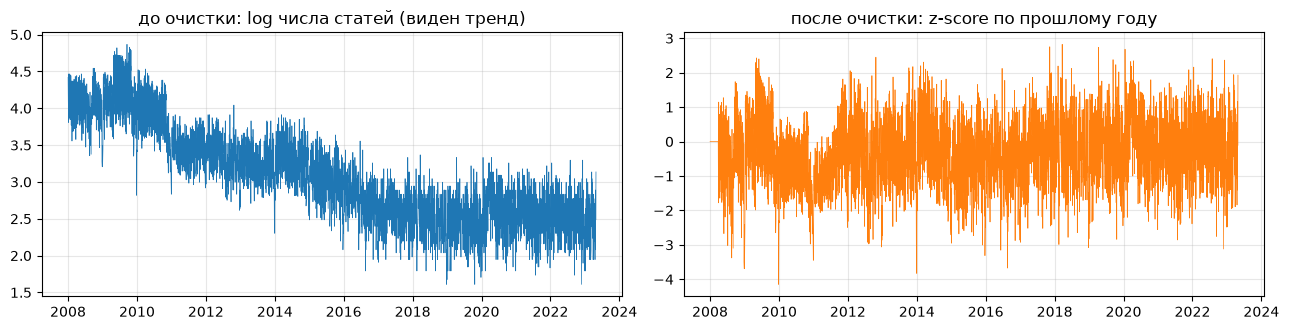

In [9]:
def past_zscore(df, window=Z_WINDOW, minp=60, clip=5):
    # z-score по прошлому окну: в день t используются только дни до t
    mu = df.rolling(window, min_periods=minp).mean().shift(1)
    sd = df.rolling(window, min_periods=minp).std().shift(1)
    return ((df - mu) / sd).clip(-clip, clip).fillna(0.0)

EMB = {k: past_zscore(v) for k, v in raw.items()}
for k, v in EMB.items():
    print(f"ε_t [{k:8s}]: {v.shape[1]} чис. в день — {list(v.columns)}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].plot(dates, raw["volume"]["log_n"], lw=0.5); ax[0].set_title("до очистки: log числа статей (виден тренд)")
ax[1].plot(dates, EMB["volume"]["log_n"], lw=0.5, color="C1"); ax[1].set_title("после очистки: z-score по прошлому году")
plt.tight_layout(); plt.show()

### 2.6. Не дублируют ли признаки друг друга?

Корреляции всех признаков на train. Если, например, первая тема TF-IDF почти совпадает с числом статей, то
«смысл» в ней — это на самом деле объём. Это поможет правильно интерпретировать результаты раздела 5.

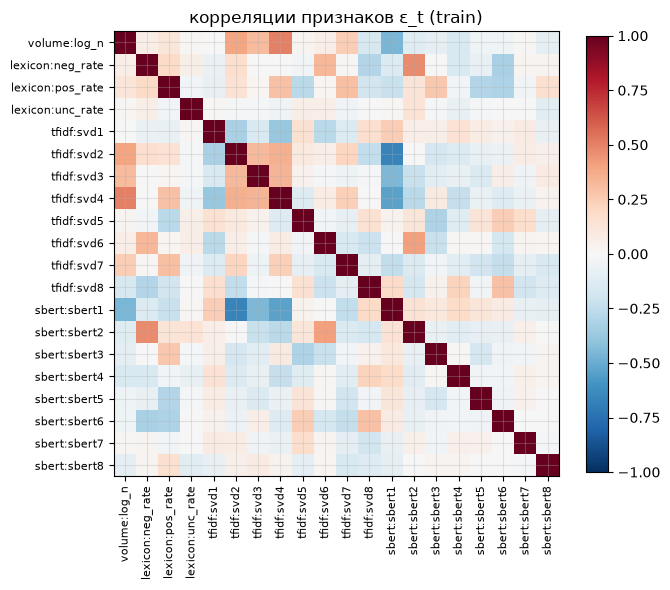

In [10]:
allfeat = pd.concat({k: v for k, v in EMB.items()}, axis=1)
allfeat.columns = [f"{a}:{b}" for a, b in allfeat.columns]
corr = allfeat[tr].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.04); ax.set_title("корреляции признаков ε_t (train)")
plt.tight_layout(); plt.show()

**Итог раздела 2:** для каждого торгового дня есть вектор $\varepsilon_t$ (в нескольких вариантах), посчитанный
только по утренним новостям и очищенный от тренда. Но рынок может реагировать не только на сегодняшние новости:
вчерашние и позавчерашние тоже ещё «в памяти». Эту память и описывает процесс Орнштейна–Уленбека.

---
# 3. Динамика: процесс Орнштейна–Уленбека («бак с дыркой»)

**Идея.** Есть скрытое состояние $x_t$ — накопленное «впечатление» рынка от новостей. Каждое утро в него доливаются
новые новости $\varepsilon_t$, а старое понемногу вытекает:

$$
x_t = A^{\Delta t}\,x_{t-1} + \varepsilon_t .
$$

Это та же формула плана $x_{t+\Delta t}=A\,x_t+\varepsilon_t$, только записанная так, чтобы индекс $t$ означал
«состояние на открытие дня $t$, когда утренние новости уже учтены».

**Если раскрыть рекурсию**, видно, что бак — это взвешенная сумма всех прошлых новостей с убывающими весами:

$$
x_t=\varepsilon_t+A^{\Delta t_t}\varepsilon_{t-1}+A^{\Delta t_t+\Delta t_{t-1}}\varepsilon_{t-2}+\dots
$$

Сегодняшние новости входят с весом 1, вчерашние — с весом $\lambda$, позавчерашние — $\lambda^2$ и т.д.

**Откуда здесь OU.** Непрерывный процесс Орнштейна–Уленбека $dx=-Kx\,dt+d\varepsilon$ при точном переходе к шагу
$\Delta t$ даёт множитель $A^{\Delta t}=e^{-K\Delta t}$. Берём $K$ диагональной — у каждой компоненты своя
скорость забывания:

$$
A=\mathrm{diag}(\lambda_1,\dots,\lambda_d),\qquad \lambda_i = 0.5^{1/h_i}\in(0,1),
$$

где $h_i$ — **период полураспада** в календарных днях: через $h_i$ дней вклад новости уменьшается вдвое.
Работать с $h$ удобнее, чем с $\lambda$: «новость живёт неделю» понятнее, чем «$\lambda=0.906$».

* $0<\lambda_i<1$ — значит $A$ **сжимающая**: всё рано или поздно забывается, процесс стационарен (не уходит в бесконечность);
* $\Delta t$ — календарные дни между сессиями: за выходные (3 дня) бак забывает в $\lambda^3$ раз, а не в $\lambda$;
* $h=0$ означает $\lambda=0$ — памяти нет, $x_t=\varepsilon_t$.

Сначала берём одну общую скорость для всех компонент ($A=\lambda I$, один параметр $h$), затем — свою для каждой
и, наконец, полную матрицу $A$ (раздел 4.4).

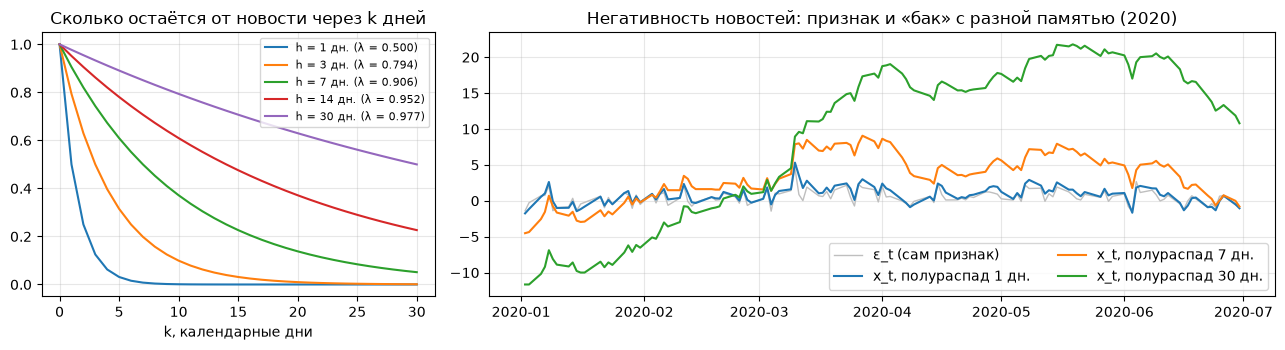

In [11]:
def ou_state(eps, gaps, half_life):
    # x_t = A^{Δt} x_{t-1} + ε_t,  A = diag(0.5^(1/h)).  half_life — число (общая A = λI) или вектор длины d
    E = np.asarray(eps, dtype=float)
    hl = np.broadcast_to(np.asarray(half_life, dtype=float), (E.shape[1],))
    safe = np.where(hl > 0, hl, 1.0)
    decay = np.where(hl > 0, 0.5 ** (np.asarray(gaps, dtype=float)[:, None] / safe), 0.0)   # A^{Δt}, форма (T, d)
    X = np.zeros_like(E)
    prev = np.zeros(E.shape[1])
    for t in range(len(E)):
        prev = decay[t] * prev + E[t]
        X[t] = prev
    return X

STATE = {}
def state(emb, h):
    # кэш: (эмбеддинг, период полураспада) → x_t
    if (emb, h) not in STATE:
        STATE[(emb, h)] = ou_state(EMB[emb].to_numpy(), gap_days, h)
    return STATE[(emb, h)]

sel = (dates >= "2020-01-01") & (dates <= "2020-06-30")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2]})
k = np.arange(0, 31)
for h in (1, 3, 7, 14, 30):
    ax[0].plot(k, 0.5 ** (k / h), label=f"h = {h} дн. (λ = {0.5 ** (1 / h):.3f})")
ax[0].set_title("Сколько остаётся от новости через k дней"); ax[0].set_xlabel("k, календарные дни"); ax[0].legend(fontsize=8)

j = list(EMB["lexicon"].columns).index("neg_rate")
ax[1].plot(dates[sel], EMB["lexicon"]["neg_rate"][sel], color="0.75", lw=1, label="ε_t (сам признак)")
for h in (1, 7, 30):
    ax[1].plot(dates[sel], state("lexicon", h)[sel, j], label=f"x_t, полураспад {h} дн.")
ax[1].set_title("Негативность новостей: признак и «бак» с разной памятью (2020)"); ax[1].legend(ncol=2)
plt.tight_layout(); plt.show()

**Что видно.** Слева — как быстро забывается одна новость при разных $h$. Справа — один и тот же признак
и бак с разной памятью: чем длиннее память, тем глаже $x_t$ и тем дольше «шлейф» после всплеска новостей.

Какая память правильная — заранее неизвестно; $h$ мы **подберём по данным** (раздел 4.4).

**Итог раздела 3:** для любого $h$ (или набора $h_i$, или матрицы $A$) состояние $x_t$ считается однозначно по новостям.
Осталось связать $x_t$ с тем, что видно на рынке, и научиться находить параметры.

---
# 4. Наблюдение $p_t=\langle g,x_t\rangle$ и алгоритмы обучения

По плану рынок «читает» состояние линейно: $p_t=\langle g,x_t\rangle$ (плюс свободный член и шум).
Сначала разберёмся, *что* именно наблюдаем (4.1–4.3), потом подробно — *как* обучается модель (4.4).

Две служебные функции, которые используются дальше везде: обучение линейной модели и $R^2$.

In [12]:
def fit_predict(F, y, fit_mask, alpha):
    # ridge y ≈ g0 + <g, F>, обучение на fit_mask; возвращает прогноз для всех дней, модель и масштаб
    F, y = np.asarray(F, dtype=float), np.asarray(y, dtype=float)
    ok = np.isfinite(F).all(axis=1) & np.isfinite(y)
    m = fit_mask & ok
    sc = StandardScaler().fit(F[m])
    model = Ridge(alpha=alpha, solver="cholesky").fit(sc.transform(F[m]), y[m])   # точная формула, без случайности
    pred = np.full(len(y), np.nan)
    pred[ok] = model.predict(sc.transform(F[ok]))
    return pred, model, sc

def r2_vs(y, p, m, ref):
    # R² относительно прогноза «константа ref»: 0 — не лучше константы, < 0 — хуже
    return 1 - np.sum((y[m] - p[m]) ** 2) / np.sum((y[m] - ref) ** 2)

def mse(y, p, m):
    return np.mean((y[m] - p[m]) ** 2)

### 4.1. Сначала буквально: цена $p_t=\langle g,x_t\rangle$

Попробуем объяснить сам логарифм цены SPY состоянием $x_t$ (TF-IDF, длинная память $h=60$ дней).

R² на train = 0.901,  R² на test = -0.45
автокорреляция остатков на train (лаг 1): 0.988


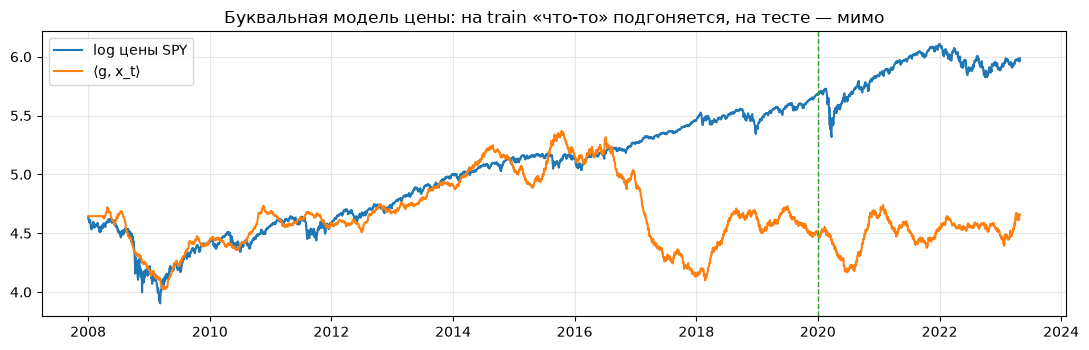

In [13]:
M0 = ohlc(TICKER).reindex(dates)
logp = np.log(M0["close"]).to_numpy()
Xp = state("tfidf", 60)
p_hat, _, _ = fit_predict(Xp, logp, masks["train"], 1.0)
ref_p = logp[masks["train"]].mean()
resid = pd.Series(logp - p_hat)
print(f"R² на train = {r2_vs(logp, p_hat, masks['train'], ref_p):.3f},  R² на test = {r2_vs(logp, p_hat, masks['test'], ref_p):.2f}")
print(f"автокорреляция остатков на train (лаг 1): {resid[masks['train']].autocorr(1):.3f}")

fig, ax = plt.subplots()
ax.plot(dates, logp, label="log цены SPY")
ax.plot(dates, p_hat, label="⟨g, x_t⟩")
ax.axvline(dates[masks["test"]][0], color="C2", ls="--", lw=1)
ax.set_title("Буквальная модель цены: на train «что-то» подгоняется, на тесте — мимо"); ax.legend()
plt.tight_layout(); plt.show()

**Почему так.** $A$ сжимающая, значит $x_t$ стационарен: колеблется вокруг постоянного уровня. Тогда и
$\langle g,x_t\rangle$ стационарна. А цена **не стационарна** — она растёт и копит информацию годами. Регрессия
одного на другое — классическая «ложная регрессия»: остатки почти не меняются день ото дня (автокорреляция ≈ 1),
и любой $R^2$ на train ничего не значит. Простая аналогия: рост ребёнка и цены на хлеб оба растут со временем,
и регрессия одного на другое даст высокий $R^2$, хотя связи нет.

### 4.2. Что наблюдаем вместо цены

Модель OU естественно описывает **стационарную** величину, которая реагирует на новости и постепенно возвращается
к норме. Такая величина на рынке — **дневная волатильность** (насколько сильно «трясёт» рынок). Её и берём как $y_t$:

$$
y_t=\log\log\frac{\text{High}_t}{\text{Low}_t}\ \ (\text{логарифм размаха сессии}),\qquad
y_t \approx g_0+\langle g,x_t\rangle + \text{база}_t .
$$

* $\log(\text{High}/\text{Low})$ — размах цены внутри сессии; он считается после 9:30, когда утренние новости уже
  известны, — подглядывания нет. Размах точнее отражает волатильность дня, чем модуль доходности: он «видит» весь
  путь цены, а не только начало и конец;
* внешний логарифм нужен, потому что размах имеет тяжёлые хвосты (2008, 2020): иначе несколько дней доминировали бы в ошибке;
* вторая цель для сравнения — доходность сессии $r_t=\log(\text{Close}_t/\text{Open}_t)$ со знаком.
  Её почти наверняка предсказать нельзя (иначе это был бы способ легко заработать); это санити-чек.

**База — что известно к 9:30 и без новостей.** Волатильность сама себя хорошо предсказывает, поэтому сравнивать
новости надо не со средним, а с моделью, которая знает историю рынка:

| признак | что это | почему важен |
|---|---|---|
| HAR: `har1`, `har5`, `har22` | размах вчера, средний за неделю и за месяц | волатильность «помнит» себя на разных горизонтах (модель HAR — стандарт в литературе) |
| `log_vix` | индекс страха VIX на вчерашнем закрытии | ожидания рынка опционов о волатильности на месяц вперёд |
| `log_abs_gap` | ночной гэп $\lvert\log(\text{Open}_t/\text{Close}_{t-1})\rvert$ | насколько рынок уже «прыгнул» за ночь; известен в 9:30 |

Обратите внимание: ночной гэп отчасти и есть реакция на утренние новости. Включая его в базу, мы спрашиваем строже:
*знают ли новости что-то сверх того, что рынок уже показал на открытии?*

дней в оценке: train 2015, val 754, test 837


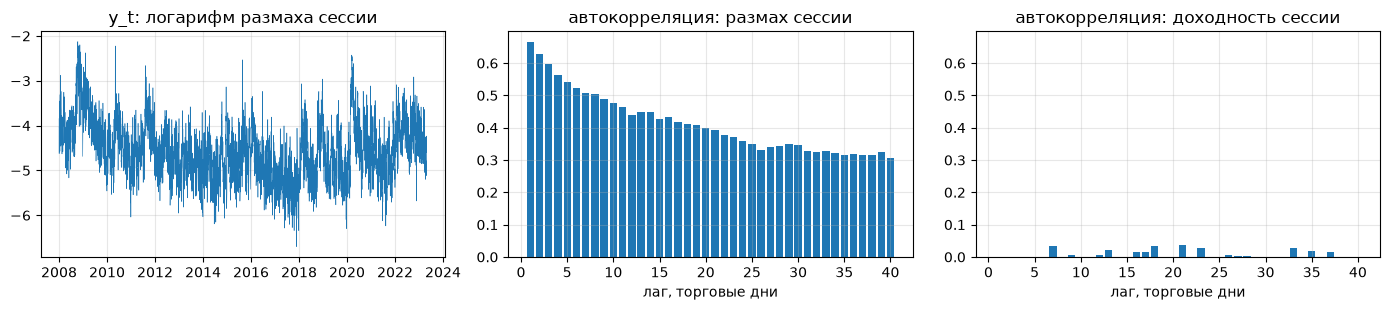

In [14]:
vix_close = prices[prices["ticker"] == "^VIX"].set_index("date")["close"].sort_index()
log_vix_lag = np.log(vix_close).shift(1)                  # вчерашнее закрытие VIX

def market_table(ticker):
    # цели и признаки «базы» для одного инструмента; всё считается на полной истории, потом режется по датам
    m = ohlc(ticker)
    m["y_range"] = np.log(np.log(m["high"] / m["low"]).where(m["high"] > m["low"]))
    m["r_oc"] = 100 * np.log(m["close"] / m["open"])
    m["y_absoc"] = np.log(m["r_oc"].abs() + 1e-3)
    m["gap"] = np.log(m["open"] / m["close"].shift(1))
    y1 = m["y_range"].shift(1)                             # только то, что известно до сессии t
    m["har1"], m["har5"], m["har22"] = y1, y1.rolling(5).mean(), y1.rolling(22).mean()
    m["log_abs_gap"] = np.log(m["gap"].abs() + 1e-4)
    m["r_oc_lag"] = m["r_oc"].shift(1)
    m["log_vix"] = log_vix_lag.reindex(m.index)
    return m.reindex(dates)

BASE_COLS = ["har1", "har5", "har22", "log_vix", "log_abs_gap"]
M = market_table(TICKER)
y = M["y_range"].to_numpy()
F_base = M[BASE_COLS].to_numpy()
ok = np.isfinite(y) & np.isfinite(F_base).all(axis=1) & (np.arange(len(dates)) >= WARMUP)

TR, VA, TE = masks["train"] & ok, masks["val"] & ok, masks["test"] & ok
TV = TR | VA
print(f"дней в оценке: train {TR.sum()}, val {VA.sum()}, test {TE.sum()}")

lags = range(1, 41)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].plot(dates, M["y_range"], lw=0.4); ax[0].set_title("y_t: логарифм размаха сессии")
for a, (name, s) in zip(ax[1:], (("размах сессии", M["y_range"]), ("доходность сессии", M["r_oc"]))):
    a.bar(list(lags), [s[ok].autocorr(l) for l in lags])
    a.set_title(f"автокорреляция: {name}"); a.set_xlabel("лаг, торговые дни")
ax[2].set_ylim(ax[1].get_ylim())
plt.tight_layout(); plt.show()

**Что видно.** У размаха автокорреляция высокая и спадает медленно — волатильность «помнит» прошлое: за бурным днём
чаще идёт бурный. У доходности — около нуля. Это и есть причина, по которой новости обязаны конкурировать с базой,
а не со средним: любой признак, просто коррелирующий с общим уровнем «нервозности», покажется полезным на фоне среднего.

### 4.3. Пример: как выглядит $g$

Одна подгонка для иллюстрации: база + `lexicon` с памятью $h=7$ дней, обучение на train.
Коэффициенты показаны «на одно стандартное отклонение признака» — так их можно сравнивать между собой.

In [15]:
F_demo = np.hstack([F_base, state("lexicon", 7)])
_, model_demo, sc_demo = fit_predict(F_demo, y, TR, 10)
g = pd.Series(model_demo.coef_, index=BASE_COLS + [f"x: {c}" for c in EMB["lexicon"].columns])
display(g.round(4).to_frame("g (на 1 ст. откл. признака)"))
print("Знак у x: neg_rate > 0 означал бы: «больше негатива в утренних новостях → шире размах дня».")

,g (на 1 ст. откл. признака)
har1,0.0687
har5,0.0841
har22,-0.0616
log_vix,0.3120
log_abs_gap,0.0615
x: neg_rate,0.0306
x: pos_rate,-0.0002
x: unc_rate,0.0155


Знак у x: neg_rate > 0 означал бы: «больше негатива в утренних новостях → шире размах дня».


**Итог 4.1–4.3:** модель собрана целиком: новости → $\varepsilon_t$ → бак $x_t$ → $y_t=g_0+\langle g,x_t\rangle$+база.
Теперь подробно о том, как находятся её параметры.

## 4.4. Алгоритмы обучения

**Что надо найти.** Параметры модели делятся на две группы:

| группа | что это | как находим |
|---|---|---|
| веса чтения $g_0, g$ | как рынок «читает» бак (и базу) | **ridge-регрессия**: точная формула, мгновенно |
| память $A$ | как быстро забываются новости | **перебор по сетке** (общая $\lambda$), **покоординатный спуск** (диагональная $A$), **градиентная оптимизация** (полная $A$) |
| сила штрафа $\alpha$ | насколько осторожна регрессия | перебор по сетке вместе с памятью |

**Главный трюк — разделить задачу на две.** Если память $A$ зафиксирована, бак $x_t$ считается однозначно (раздел 3),
и задача превращается в обычную линейную регрессию — её решение известно точной формулой. Поэтому:

```
для каждого кандидата памяти A:
    1. посчитать бак x_t по новостям          (раздел 3)
    2. найти g ridge-регрессией на train       (точная формула)
    3. посчитать ошибку на val
выбрать A с наименьшей ошибкой на val
```

Это называется **профильной оптимизацией**: внешний поиск идёт только по параметрам памяти, а $g$ для каждого
кандидата находится «внутри» точно. Так задача из многомерной становится маленькой: для общей $\lambda$ — одномерный перебор.

**Почему эмбеддинг не учим вместе с $A$ и $g$.** Если одновременно крутить и эмбеддинг, и $A$, и $g$, одно и то же
поведение можно получить многими способами (например, повернув координаты бака), и параметры перестают быть
однозначными. Поэтому порядок строгий: сначала текст → $\varepsilon_t$ (на train), потом динамика.

### 4.4.1. Протокол: train → val → test

```
 2008 ─────────── 2016 │ 2017 ── 2019 │ 2020 ──── 2023
        train           │     val      │     test
  учим g при каждом      │ выбираем h, α │ смотрим ОДИН раз,
  кандидате (h, α)       │ по ошибке     │ после того как всё выбрано
                         └───────┬──────┘
               финальная модель переобучается на train+val
```

Почему нельзя выбирать $h$ по тесту: если перепробовать много вариантов и выбрать лучший по тесту, тест перестаёт
быть «новыми данными» — мы фактически на нём обучились, и оценка качества получится завышенной.

### 4.4.2. Веса $g$: ridge-регрессия

Обычная линейная регрессия ищет $g$, минимизирующий сумму квадратов ошибок. Ridge добавляет штраф за величину коэффициентов:

$$
\hat g=\arg\min_g\ \sum_t\bigl(y_t-g_0-\langle g,z_t\rangle\bigr)^2+\alpha\lVert g\rVert^2
\quad\Longrightarrow\quad
\hat g=(Z^\top Z+\alpha I)^{-1}Z^\top(y-\bar y).
$$

Здесь $Z$ — матрица признаков (база и бак), **стандартизованная** по train: каждый столбец минус своё среднее
и делённый на своё стандартное отклонение. Зачем:

* **штраф $\alpha$** «тянет» коэффициенты к нулю. При $\alpha=0$ — обычная регрессия; чем больше $\alpha$, тем
  осторожнее модель. Это особенно важно, когда сигнал слабый, а признаков много: без штрафа регрессия начинает
  подгоняться под шум;
* **стандартизация** нужна, чтобы штраф действовал на все признаки одинаково: иначе признак, измеренный в маленьких
  единицах (и поэтому с большим коэффициентом), штрафовался бы сильнее;
* свободный член $g_0$ не штрафуется — он просто равен среднему $y$.

Проверим, что библиотечная `Ridge` делает ровно то, что написано в формуле:

максимальное расхождение формулы и sklearn: 2.3869795029440866e-15


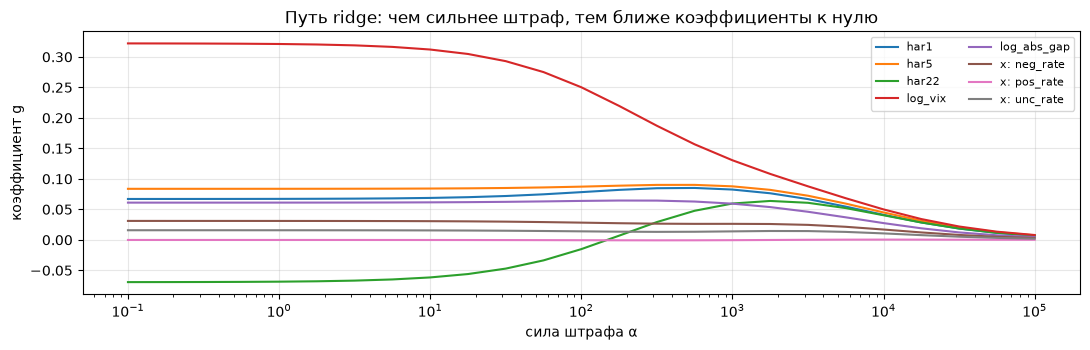

In [16]:
alpha_demo = 10
Z = sc_demo.transform(F_demo[TR])                       # стандартизованные признаки train
yc = y[TR] - y[TR].mean()
g_formula = np.linalg.solve(Z.T @ Z + alpha_demo * np.eye(Z.shape[1]), Z.T @ yc)
print("максимальное расхождение формулы и sklearn:", float(np.max(np.abs(g_formula - model_demo.coef_))))

# как штраф сжимает коэффициенты
alphas_path = np.logspace(-1, 5, 25)
path = np.array([np.linalg.solve(Z.T @ Z + a * np.eye(Z.shape[1]), Z.T @ yc) for a in alphas_path])
fig, ax = plt.subplots()
for i, name in enumerate(g.index):
    ax.plot(alphas_path, path[:, i], label=name)
ax.set_xscale("log"); ax.set_xlabel("сила штрафа α"); ax.set_ylabel("коэффициент g")
ax.set_title("Путь ridge: чем сильнее штраф, тем ближе коэффициенты к нулю"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

**Как читать.** Расхождение порядка $10^{-12}$ — формула и библиотека совпадают. На графике видно, как при росте
$\alpha$ коэффициенты плавно уходят к нулю. Первыми «сдаются» признаки, которые слабо связаны с целью;
дольше всех держатся сильные (обычно VIX и HAR). Правильное $\alpha$ выбирается на валидации.

### 4.4.3. Общая память $A=\lambda I$: перебор по сетке

Параметр один — период полураспада $h$ (плюс $\alpha$). Перебираем все пары $(h,\alpha)$ из сетки, для каждой обучаем
$g$ на train и считаем ошибку на val. Почему перебор, а не градиентный спуск:

* параметр всего один — 36 вариантов считаются за секунды;
* функция ошибки от $h$ может иметь несколько локальных минимумов — перебор их не боится;
* весь «ландшафт» ошибки можно нарисовать и **увидеть**, насколько уверенно выбран $h$.

Ниже — этот ландшафт для каждого эмбеддинга: $R^2$ на валидации как функция $h$ (при лучшем $\alpha$),
и тепловая карта по $(h,\alpha)$ для одного эмбеддинга.

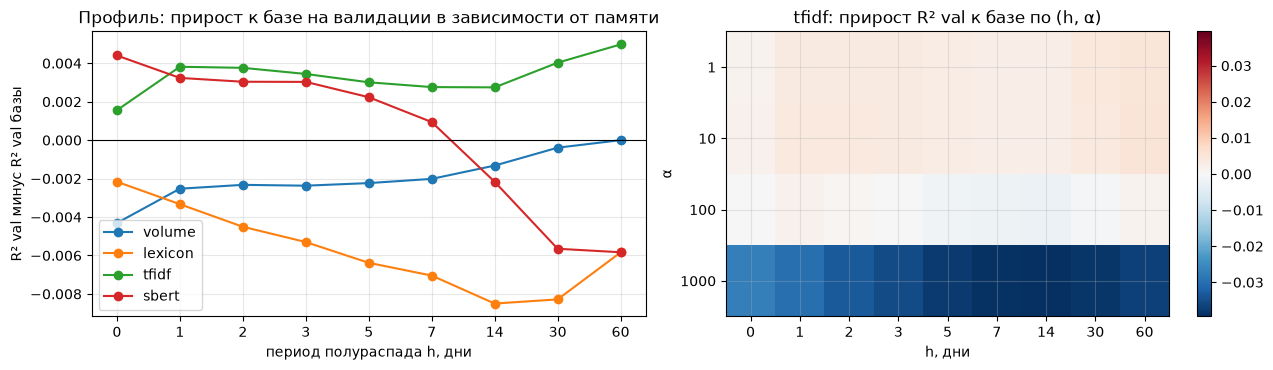

,h,α,R² val
база,0.0,10.0,0.6398
база + volume,60.0,10.0,0.6398
база + lexicon,0.0,10.0,0.6376
база + tfidf,60.0,10.0,0.6448
база + sbert,0.0,10.0,0.6442


In [17]:
def select(make_F, y, ok, half_lives=HALF_LIVES, alphas=ALPHAS):
    # перебор (h, alpha): обучаем на train, выбираем по MSE на val; возвращает лучшее и всю сетку
    tr, va = masks["train"] & ok, masks["val"] & ok
    base_mse = np.mean((y[va] - y[tr].mean()) ** 2)
    grid = []
    for h in half_lives:
        F = make_F(h)
        for a in alphas:
            p = fit_predict(F, y, tr, a)[0]
            grid.append({"h": h, "alpha": a, "val_mse": np.mean((y[va] - p[va]) ** 2)})
    grid = pd.DataFrame(grid)
    grid["R² val"] = 1 - grid["val_mse"] / base_mse
    b = grid.loc[grid["val_mse"].idxmin()]
    return {"half_life": int(b["h"]), "alpha": float(b["alpha"]), "R² val": float(b["R² val"]), "grid": grid}

INFO = {}
INFO["база"] = select(lambda h: F_base, y, ok, half_lives=[0])
for emb in EMB:
    INFO[f"база + {emb}"] = select(lambda h, emb=emb: np.hstack([F_base, state(emb, h)]), y, ok)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
base_r2 = INFO["база"]["R² val"]
for emb in EMB:
    gr = INFO[f"база + {emb}"]["grid"].groupby("h")["R² val"].max()
    ax[0].plot(range(len(gr)), gr.values - base_r2, marker="o", label=emb)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_xticks(range(len(HALF_LIVES))); ax[0].set_xticklabels(HALF_LIVES)
ax[0].set_xlabel("период полураспада h, дни"); ax[0].set_ylabel("R² val минус R² val базы")
ax[0].set_title("Профиль: прирост к базе на валидации в зависимости от памяти"); ax[0].legend()

best_emb = max(EMB, key=lambda e: INFO[f"база + {e}"]["R² val"])
heat = INFO[f"база + {best_emb}"]["grid"].pivot(index="alpha", columns="h", values="R² val") - base_r2
im = ax[1].imshow(heat.values, aspect="auto", cmap="RdBu_r",
                  vmin=-np.abs(heat.values).max(), vmax=np.abs(heat.values).max())
ax[1].set_xticks(range(heat.shape[1])); ax[1].set_xticklabels(heat.columns)
ax[1].set_yticks(range(heat.shape[0])); ax[1].set_yticklabels(heat.index)
ax[1].set_xlabel("h, дни"); ax[1].set_ylabel("α")
ax[1].set_title(f"{best_emb}: прирост R² val к базе по (h, α)")
plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()

display(pd.DataFrame({k: {"h": v["half_life"], "α": v["alpha"], "R² val": round(v["R² val"], 4)}
                      for k, v in INFO.items()}).T)

**Как читать.**

* Слева: кривая выше нуля — бак с такой памятью помогает базе на валидации. **Плоская кривая** около нуля — память
  ни на что не влияет, и выбранный $h$ почти случаен (вспомните синтетику в разделе 5.2: при слабом сигнале так и бывает).
  **Острый пик** — данные уверенно указывают на конкретную память.
* Справа: синие клетки — лучше базы, красные — хуже. Если хорошая область широкая, результат не зависит от точного выбора
  настроек — это хороший знак. Одна синяя клетка среди красных — скорее случайность.

### 4.4.4. Диагональная $A$: покоординатный спуск

Теперь у каждой компоненты $\varepsilon$ свой период полураспада $h_1,\dots,h_d$. Полный перебор невозможен:
при 9 кандидатах и 8 компонентах это $9^8\approx 43$ млн вариантов. Поэтому **покоординатный спуск**:

```
начать с общего h для всех компонент (результат 4.4.3)
повторить 2 раза:
    для каждой компоненты i = 1..d:
        перебрать h_i по сетке, остальные h_j держать фиксированными
        оставить h_i с наименьшей ошибкой на val
```

Каждый шаг не ухудшает ошибку на валидации, поэтому алгоритм сходится, хотя и не обязательно к глобальному минимуму.
Цена: $2\cdot d\cdot 9$ подгонок вместо 43 млн. Опасность: параметров стало больше, а валидация та же — растёт риск
**подогнаться под валидацию**. Поэтому решает только тест (раздел 5.5).

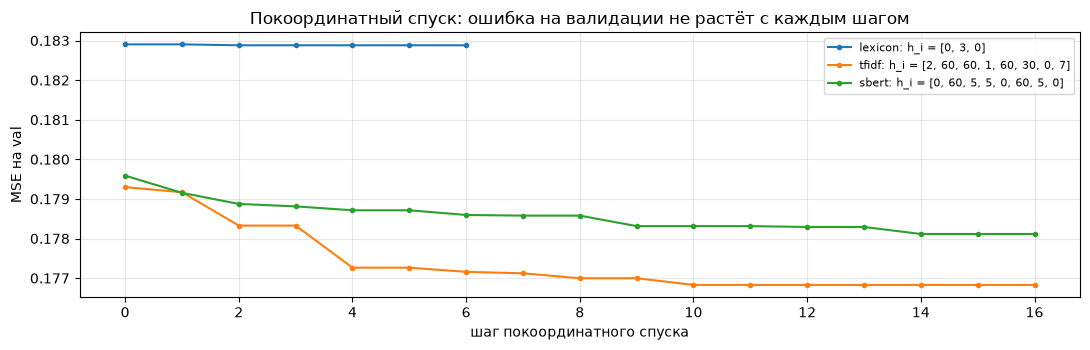

In [18]:
COMP = {}
def comp_state(emb, j, h):
    if (emb, j, h) not in COMP:
        COMP[(emb, j, h)] = ou_state(EMB[emb].to_numpy()[:, [j]], gap_days, h)
    return COMP[(emb, j, h)]

def fit_diagonal(emb, passes=2, verbose=False):
    s = INFO[f"база + {emb}"]
    d = EMB[emb].shape[1]
    hl = [s["half_life"]] * d                          # старт — общий h
    F_of = lambda v: np.hstack([F_base] + [comp_state(emb, j, h) for j, h in enumerate(v)])
    val_mse = lambda v: mse(y, fit_predict(F_of(v), y, TR, s["alpha"])[0], VA)
    history = [val_mse(hl)]
    for _ in range(passes):
        for j in range(d):
            scores = {h: val_mse(hl[:j] + [h] + hl[j + 1:]) for h in HALF_LIVES}
            hl[j] = min(scores, key=scores.get)
            history.append(scores[hl[j]])
    return hl, F_of(hl), history

DIAG = {}
fig, ax = plt.subplots()
for emb in EMB:
    if EMB[emb].shape[1] < 2:
        continue
    hl, F_diag, hist = fit_diagonal(emb)
    DIAG[emb] = {"h": hl, "F": F_diag}
    ax.plot(hist, marker=".", label=f"{emb}: h_i = {hl}")
ax.set_xlabel("шаг покоординатного спуска"); ax.set_ylabel("MSE на val")
ax.set_title("Покоординатный спуск: ошибка на валидации не растёт с каждым шагом"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4.4.5. Полная матрица $A$: градиентная оптимизация

Самый общий вариант плана: $A$ — любая сжимающая матрица $d\times d$. Компоненты бака теперь могут влиять друг на друга
(например, «новости о ФРС» сегодня могут усиливать «новости о банках» завтра).

**Как гарантировать, что $A$ сжимающая.** Оптимизатор ищет не саму $A$, а свободные числа: матрицу $M$ и число $\theta$.
Из них $A$ строится так:

$$
A=\rho\,\frac{M}{\lVert M\rVert_2},\qquad \rho=\frac{0.99}{1+e^{-\theta}}\in(0,\,0.99),
$$

где $\lVert M\rVert_2$ — спектральная норма (наибольшее растяжение вектора). Тогда $\lVert A\rVert_2=\rho<1$: любая
$A$, которую может предложить оптимизатор, автоматически сжимающая, и никаких ограничений проверять не нужно.

**Алгоритм.**

1. Старт — решение с общей памятью: $M=I$, $\rho=\lambda$ из раздела 4.4.3. Значит, полная $A$ на train не может
   оказаться хуже общей $\lambda$.
2. Функция потерь — MSE на **train**: для данной $A$ считаем бак, находим $g$ ridge-регрессией (профильный трюк),
   считаем ошибку.
3. Минимизируем методом **L-BFGS** — это градиентный метод, который по истории шагов приближённо учитывает кривизну
   функции и поэтому сходится быстрее простого градиентного спуска. Градиент считается численно: каждый параметр
   немного сдвигают и смотрят, как меняется ошибка.
4. Параметров $d^2+1$: для 3 компонент — 10, для 8 — 65. Чем их больше, тем выше риск переобучения на слабом сигнале,
   поэтому на реальных данных берём не больше 4 компонент.

Сначала — **проверка на синтетике**: генерируем данные с известной полной $A$ (с вращением, которое диагональная $A$
описать не может) и смотрим, восстановит ли её алгоритм.

In [19]:
def ou_state_full(eps, gaps, A):
    # x_t = A^{Δt} x_{t-1} + ε_t для произвольной матрицы A (Δt — целое число календарных дней)
    E = np.asarray(eps, dtype=float)
    steps = np.maximum(np.round(np.asarray(gaps)).astype(int), 1)
    powers = {k: np.linalg.matrix_power(A, k) for k in np.unique(steps)}
    X = np.zeros_like(E)
    prev = np.zeros(E.shape[1])
    for t in range(len(E)):
        prev = powers[steps[t]] @ prev + E[t]
        X[t] = prev
    return X

def A_from_params(z, d, rho_max=0.99):
    Mx = np.asarray(z[:d * d]).reshape(d, d)
    rho = rho_max / (1 + np.exp(-z[-1]))
    return rho * Mx / max(np.linalg.norm(Mx, 2), 1e-12)

def fit_full_A(E, yv, Fb, fit_mask, alpha, h0, maxiter=60):
    # профильная оптимизация: внешне по A (L-BFGS), внутри g — ridge
    d = E.shape[1]
    lam0 = min(0.5 ** (1 / h0), 0.98) if h0 > 0 else 0.05
    z0 = np.r_[np.eye(d).ravel(), np.log(lam0 / (0.99 - lam0))]
    design = lambda A: ou_state_full(E, gap_days, A) if Fb is None else np.hstack([Fb, ou_state_full(E, gap_days, A)])
    def loss(z):
        return mse(yv, fit_predict(design(A_from_params(z, d)), yv, fit_mask, alpha)[0], fit_mask)
    res = minimize(loss, z0, method="L-BFGS-B", options={"maxiter": maxiter})
    A = A_from_params(res.x, d)
    return A, design(A), res

# --- синтетика: полная A с вращением в первых двух координатах
th = 0.4
A_true = np.array([[np.cos(th), -np.sin(th), 0], [np.sin(th), np.cos(th), 0], [0, 0, 0.6]]) * np.array([0.9, 0.9, 1])[:, None]
r_syn = make_rng(101)
E_syn = r_syn.standard_normal((len(dates), 3))
x_syn = ou_state_full(E_syn, gap_days, A_true)
sig = x_syn @ np.array([1.0, -0.5, 0.8])
y_syn = (sig - sig.mean()) / sig.std() * np.sqrt(0.3) + r_syn.standard_normal(len(dates)) * np.sqrt(0.7)
all_ok = np.ones(len(dates), bool)

s_scalar = select(lambda h: ou_state(E_syn, gap_days, h), y_syn, all_ok, alphas=[1])
A_hat, F_hat, res = fit_full_A(E_syn, y_syn, None, masks["train"], 1, s_scalar["half_life"])
p_full = fit_predict(F_hat, y_syn, masks["train"], 1)[0]
p_scal = fit_predict(ou_state(E_syn, gap_days, s_scalar["half_life"]), y_syn, masks["train"], 1)[0]
ref_s = y_syn[masks["train"]].mean()
print("истинная A:\n", A_true.round(3))
print("найденная A:\n", A_hat.round(3))
print("|собств. числа| истинные:", np.sort(np.abs(np.linalg.eigvals(A_true)))[::-1].round(3),
      " найденные:", np.sort(np.abs(np.linalg.eigvals(A_hat)))[::-1].round(3))
print(f"R² val: общая λ = {r2_vs(y_syn, p_scal, masks['val'], ref_s):.3f},  полная A = {r2_vs(y_syn, p_full, masks['val'], ref_s):.3f}"
      f"   (истинная доля сигнала 0.30; итераций L-BFGS: {res.nit})")

истинная A:
 [[ 0.829 -0.35   0.   ]
 [ 0.35   0.829  0.   ]
 [ 0.     0.     0.6  ]]
найденная A:
 [[ 0.887 -0.344 -0.021]
 [ 0.379  0.77   0.018]
 [ 0.06  -0.027  0.61 ]]
|собств. числа| истинные: [0.9 0.9 0.6]  найденные: [0.902 0.902 0.611]
R² val: общая λ = 0.146,  полная A = 0.315   (истинная доля сигнала 0.30; итераций L-BFGS: 47)


**Как читать.** Если найденная $A$ близка к истинной (в том числе внедиагональные элементы — вращение), а $R^2$ на
валидации у полной $A$ заметно выше, чем у общей $\lambda$, — алгоритм работает, и при *сильном* сигнале полная $A$
действительно умеет то, чего не умеет диагональная. На реальных данных применим его в разделе 5.5 — там сигнал
гораздо слабее, и вопрос в том, окупятся ли лишние параметры.

**Итог раздела 4:** все три алгоритма обучения памяти — перебор, покоординатный спуск, градиентная оптимизация —
построены на одном трюке: при фиксированной $A$ веса $g$ находятся точно. Выбор настроек — только на валидации.
Переходим к главному — проверке качества.

---
# 5. Проверка качества

Проверяем в таком порядке — от «работает ли сам метод» к «есть ли сигнал в реальных данных»:

| блок | вопрос |
|---|---|
| 5.1 метрики | как мы измеряем «лучше» и «значимо лучше» |
| 5.2 синтетика | находит ли метод известный ответ при реалистичном уровне шума |
| 5.3 бейзлайны | насколько хорошо рынок предсказывается без новостей |
| 5.4 главная таблица | добавляют ли новости что-то к базе |
| 5.5 сложнее $A$ | окупаются ли диагональная и полная $A$ |
| 5.6 плацебо | не случайность ли это |
| 5.7 по годам | не набран ли результат за один год |
| 5.8 форма памяти | правда ли влияние новости затухает экспоненциально |
| 5.9 какие компоненты | какие именно признаки новостей работают |

Финальные модели обучаются на train+val с настройками, выбранными на val, и оцениваются на тесте.

## 5.1. Метрики

* **$R^2$ на тесте** относительно прогноза «среднее по train+val». Почему не по среднему теста: среднее теста в момент
  прогноза неизвестно, сравнивать с ним — подглядывание.
* **$\Delta$MSE vs база, %** $=100\cdot(1-\text{MSE}_\text{новая}/\text{MSE}_\text{база})$. Показывает, насколько
  уменьшилась ошибка. Для волатильности хорошая добавка — единицы процентов; доли процента — почти ничего.
* **IC** — ранговая корреляция Спирмена прогноза и факта.
* **Тест Кларка–Уэста (CW).** Модель «база + новости» содержит базу как частный случай (при $g_\text{news}=0$).
  Для таких *вложенных* моделей простое сравнение MSE несправедливо к большой модели: даже если новости полезны,
  оценка их лишних коэффициентов добавляет шум. CW вносит поправку на этот шум:
  $$f_t=(y_t-\hat y^{\text{база}}_t)^2-(y_t-\hat y^{\text{нов}}_t)^2+(\hat y^{\text{база}}_t-\hat y^{\text{нов}}_t)^2,$$
  и проверяет, что среднее $f_t$ больше нуля. Стандартная ошибка считается по Ньюи–Уэсту — с поправкой на то, что
  соседние дни зависимы (обычные p-value здесь были бы слишком оптимистичны).
* **Статистическая и практическая значимость — не одно и то же.** На тысячах дней тест может уверенно сказать,
  что прирост «не ноль», даже если он равен тысячным долям процента. Поэтому кроме p-value требуем, чтобы прирост был
  **заметным**: не меньше `MIN_GAIN` = 0.5% MSE.
* **Поправка Холма.** Проверяем несколько эмбеддингов сразу. Холм упорядочивает p-value и умножает самое маленькое
  на число проверок, следующее — на число проверок минус один и т.д.

In [20]:
def gain(y, p_new, p_base, m):
    # на сколько % ошибка новой модели меньше, чем у базовой (> 0 — новая лучше)
    return 100 * (1 - mse(y, p_new, m) / mse(y, p_base, m))

def newey_west_se(x, lags=10):
    x = np.asarray(x, float) - np.mean(x)
    n = len(x)
    s = x @ x / n
    for l in range(1, lags + 1):
        s += 2 * (1 - l / (lags + 1)) * (x[l:] @ x[:-l]) / n
    return np.sqrt(max(s, 0) / n)

def clark_west(y, p_base, p_new, lags=10):
    # тест Кларка–Уэста для вложенных моделей: H0 — новые признаки не улучшают прогноз. p односторонний.
    f = (y - p_base) ** 2 - (y - p_new) ** 2 + (p_base - p_new) ** 2
    t = f.mean() / newey_west_se(f, lags)
    return t, 1 - norm.cdf(t)

def holm(pvals):
    # поправка Холма на множественные сравнения
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(running, 1.0)
    return adj

def ols_hac(X, yv, lags):
    # МНК с ошибками Ньюи–Уэста: коэффициенты и их стандартные ошибки
    Xm = np.column_stack([np.ones(len(yv)), X])
    beta = np.linalg.lstsq(Xm, yv, rcond=None)[0]
    e = yv - Xm @ beta
    Xe = Xm * e[:, None]
    n = len(yv)
    S = Xe.T @ Xe / n
    for l in range(1, lags + 1):
        G = Xe[l:].T @ Xe[:-l] / n
        S += (1 - l / (lags + 1)) * (G + G.T)
    Qi = np.linalg.inv(Xm.T @ Xm / n)
    return beta, np.sqrt(np.diag(Qi @ S @ Qi / n))

## 5.2. Синтетика: умеет ли метод находить сигнал?

Прежде чем смотреть на рынок, проверяем метод там, где ответ **известен**. Генерируем случайные «новости»,
пропускаем их через бак с периодом полураспада **7 дней** (на настоящем календаре, с выходными), делаем
цель = сигнал + шум и смотрим, какой $h$ выберет валидация.

`share` — доля дисперсии цели, объяснённая сигналом. На рынке разумно ждать доли процента.
Если метод не находит ответ при таком уровне шума, то «ничего не нашли» на реальных данных будет означать
«не хватило мощности», а не «сигнала нет».

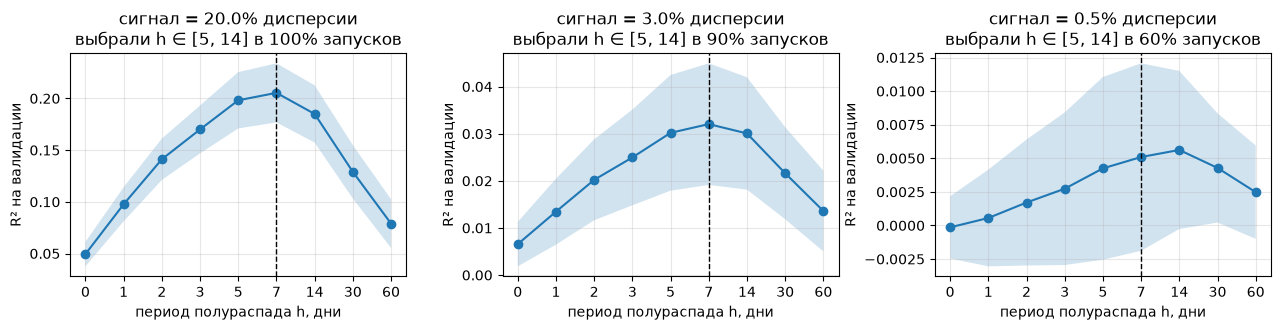

In [21]:
def synthetic_run(share, seed, d=3, true_h=7):
    r = make_rng(201, seed)
    eps = r.standard_normal((len(dates), d))
    s = ou_state(eps, gap_days, true_h) @ r.standard_normal(d)
    s = (s - s.mean()) / s.std()
    ys = np.sqrt(share) * s + np.sqrt(1 - share) * r.standard_normal(len(dates))
    scores = []
    for h in HALF_LIVES:
        p = fit_predict(ou_state(eps, gap_days, h), ys, masks["train"], 1.0)[0]
        scores.append(r2_vs(ys, p, masks["val"], ys[masks["train"]].mean()))
    return np.array(scores)

SHARES = [0.20, 0.03, 0.005]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, sh in zip(axs, SHARES):
    runs = np.array([synthetic_run(sh, s) for s in range(20)])
    best_h = np.array(HALF_LIVES)[runs.argmax(axis=1)]
    hit = np.isin(best_h, [5, 7, 14]).mean()
    xs = np.arange(len(HALF_LIVES))
    ax.plot(xs, runs.mean(0), marker="o")
    ax.fill_between(xs, runs.mean(0) - runs.std(0), runs.mean(0) + runs.std(0), alpha=0.2)
    ax.axvline(HALF_LIVES.index(7), color="k", ls="--", lw=1)
    ax.set_xticks(xs); ax.set_xticklabels(HALF_LIVES)
    ax.set_title(f"сигнал = {sh:.1%} дисперсии\nвыбрали h ∈ [5, 14] в {hit:.0%} запусков")
    ax.set_xlabel("период полураспада h, дни"); ax.set_ylabel("R² на валидации")
plt.tight_layout(); plt.show()

**Как читать.** Пунктир — истинный ответ (7 дней), линия — среднее по 20 запускам, полоса — разброс.
При сильном сигнале пик чётко на правильном месте — код без ошибок. При слабом пик размывается: точное значение
памяти на реальных данных мы, скорее всего, не определим, и к «красивым» значениям $h$ надо относиться осторожно.

Метод проверен. Переходим к реальным данным — и начинаем **без новостей**.

## 5.3. Бейзлайны: что известно без новостей

Лестница моделей, каждая следующая знает чуть больше:

| модель | что знает |
|---|---|
| `mean` | среднее по train+val — «ничего не знаю» |
| `HAR` | собственную историю размаха (1, 5, 22 дня) |
| `база` | HAR + VIX + ночной гэп — всё, что известно к 9:30 без новостей |

,полураспад h,R² val,R² test,IC test
модель,,,,
mean,,NaN,0.0000,NaN
HAR,0,0.6065,0.5948,0.6799
база,0,0.6398,0.6272,0.7130


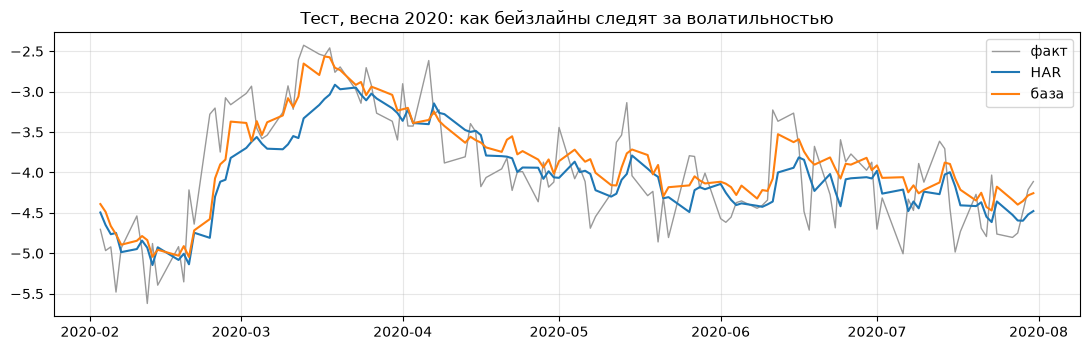

In [22]:
ref = y[TV].mean()
P = {}
P["mean"] = np.full(len(y), ref)
F_har = M[["har1", "har5", "har22"]].to_numpy()
INFO["HAR"] = select(lambda h: F_har, y, ok, half_lives=[0])
P["HAR"] = fit_predict(F_har, y, TV, INFO["HAR"]["alpha"])[0]
P["база"] = fit_predict(F_base, y, TV, INFO["база"]["alpha"])[0]

def row(name):
    p = P[name]
    out = {"модель": name, "полураспад h": INFO.get(name, {}).get("half_life", ""),
           "R² val": INFO.get(name, {}).get("R² val", np.nan),
           "R² test": r2_vs(y, p, TE, ref),
           "IC test": spearmanr(p[TE], y[TE])[0] if np.std(p[TE]) > 0 else np.nan}
    if name.startswith("база + "):              # сравнение с базой имеет смысл только для вложенных моделей
        out["Δ MSE vs база, %"] = gain(y, p, P["база"], TE)
        out["CW p"] = clark_west(y[TE], P["база"][TE], p[TE])[1]
    return out

display(pd.DataFrame([row(n) for n in P]).set_index("модель").round(4))

fig, ax = plt.subplots()
show = TE & (dates >= "2020-02-01") & (dates <= "2020-07-31")
ax.plot(dates[show], y[show], color="0.6", lw=1, label="факт")
ax.plot(dates[show], P["HAR"][show], label="HAR")
ax.plot(dates[show], P["база"][show], label="база")
ax.set_title("Тест, весна 2020: как бейзлайны следят за волатильностью"); ax.legend()
plt.tight_layout(); plt.show()

**Что ожидать.** HAR должен заметно бить `mean`, а `база` — HAR: волатильность хорошо предсказуема по истории рынка,
VIX и гэпу. Это та планка, которую новости должны перепрыгнуть. На графике видно, что базовые модели запаздывают
на резких разворотах — именно в такие дни у новостей есть шанс помочь.

## 5.4. Модели с новостями — главная таблица

Для каждого эмбеддинга две модели:

* `новости: …` — только бак $x_t$, без базы: есть ли в новостях *хоть какая-то* информация о волатильности;
* `база + …` — **главный вопрос**: даёт ли бак что-то **сверх** базы.

Настройки `база + …` уже выбраны в разделе 4.4.3; здесь переобучаем на train+val и смотрим тест.

In [23]:
for emb in EMB:
    news_F = lambda h, emb=emb: state(emb, h)
    INFO[f"новости: {emb}"] = s = select(news_F, y, ok)
    P[f"новости: {emb}"] = fit_predict(news_F(s["half_life"]), y, TV, s["alpha"])[0]
    s = INFO[f"база + {emb}"]
    P[f"база + {emb}"] = fit_predict(np.hstack([F_base, state(emb, s["half_life"])]), y, TV, s["alpha"])[0]

main = pd.DataFrame([row(n) for n in P]).set_index("модель")
fam = [n for n in main.index if n.startswith("база + ")]
main.loc[fam, "CW p (Холм)"] = holm(main.loc[fam, "CW p"])
display(main.round(4))

,полураспад h,R² val,R² test,IC test,"Δ MSE vs база, %",CW p,CW p (Холм)
модель,,,,,,,
mean,,NaN,0.0000,NaN,NaN,NaN,NaN
HAR,0,0.6065,0.5948,0.6799,NaN,NaN,NaN
база,0,0.6398,0.6272,0.7130,NaN,NaN,NaN
новости: volume,60,-0.0044,0.0246,0.2609,NaN,NaN,NaN
база + volume,60,0.6398,0.6272,0.7130,0.0009,0.0001,0.0003
новости: lexicon,0,-0.0133,0.0316,0.1694,NaN,NaN,NaN
база + lexicon,0,0.6376,0.6282,0.7145,0.2599,0.0515,0.1031
новости: tfidf,0,-0.0393,-0.0001,0.1254,NaN,NaN,NaN
база + tfidf,60,0.6448,0.6019,0.7099,-6.8038,0.9977,0.9977


**Как интерпретировать (сверху вниз):**

1. `новости: …` с R² test > 0 — новости *что-то* знают о волатильности. Но это может быть то же самое, что уже знает база
   (например, в нервные дни просто больше пишут).
2. `база + …` против `база` — **главная проверка**. Прирост в доли процента и p > 0.05 (с поправкой Холма) означают,
   что новости ничего не добавили.
3. `volume` против `lexicon` / `tfidf`: если простое число статей не хуже — работает «шумность дня», а не смысл.
4. Сравните `R² val` и `R² test`: если на валидации прирост был, а на тесте пропал, — скорее всего, настройки
   подогнались под валидацию.

## 5.5. Окупаются ли диагональная и полная $A$?

Сравниваем на тесте три варианта памяти для каждого эмбеддинга: общая $\lambda$, диагональная $A$ (из 4.4.4) и полная
$A$ (из 4.4.5; для `tfidf`/`sbert` — по первым 4 компонентам, чтобы не было 65 параметров на слабом сигнале).

In [24]:
rows = []
FULL = {}
for emb in EMB:
    s = INFO[f"база + {emb}"]
    r = {"эмбеддинг": emb, "общая λ: h": s["half_life"],
         "Δ MSE: общая λ, %": gain(y, P[f"база + {emb}"], P["база"], TE)}
    if emb in DIAG:
        p_diag = fit_predict(DIAG[emb]["F"], y, TV, s["alpha"])[0]
        r["диагональная: h_i"] = DIAG[emb]["h"]
        r["Δ MSE: диагональная, %"] = gain(y, p_diag, P["база"], TE)
    if EMB[emb].shape[1] >= 2:
        E_f = EMB[emb].to_numpy()[:, :4]
        A_f, F_f, res_f = fit_full_A(E_f, y, F_base, TR, s["alpha"], s["half_life"])
        FULL[emb] = A_f
        p_full = fit_predict(F_f, y, TV, s["alpha"])[0]
        r["полная: ‖A‖₂"] = round(float(np.linalg.norm(A_f, 2)), 3)
        r["Δ MSE: полная, %"] = gain(y, p_full, P["база"], TE)
        r["CW p (полная)"] = clark_west(y[TE], P["база"][TE], p_full[TE])[1]
    rows.append(r)
display(pd.DataFrame(rows).set_index("эмбеддинг").round(4))
for emb, A_f in FULL.items():
    print(f"полная A для {emb} (первые {A_f.shape[0]} компоненты):\n{A_f.round(3)}")

,общая λ: h,"Δ MSE: общая λ, %",диагональная: h_i,"Δ MSE: диагональная, %",полная: ‖A‖₂,"Δ MSE: полная, %",CW p (полная)
эмбеддинг,,,,,,,
volume,60,0.0009,NaN,NaN,NaN,NaN,NaN
lexicon,0,0.2599,"[0, 3, 0]",-0.0153,0.021,0.2662,0.0500
tfidf,60,-6.8038,"[2, 60, 60, 1, 60, 30, 0, 7]",-8.3561,0.985,-2.2614,0.9011
sbert,0,0.6996,"[0, 60, 5, 5, 0, 60, 5, 0]",2.1447,0.990,-0.0725,0.0808


полная A для lexicon (первые 3 компоненты):
[[0.002 0.    0.009]
 [0.002 0.016 0.004]
 [0.002 0.003 0.017]]
полная A для tfidf (первые 4 компоненты):
[[ 0.644  0.499 -0.08   0.007]
 [-0.208  0.577  0.581 -0.194]
 [-0.029 -0.413  0.491 -0.545]
 [-0.533  0.259  0.172  0.476]]
полная A для sbert (первые 4 компоненты):
[[ 0.482  0.347  0.258 -0.573]
 [-0.402  0.388 -0.143 -0.318]
 [ 0.083  0.4    0.045 -0.208]
 [ 0.72  -0.198 -0.007  0.187]]


**Как читать.** Если диагональная или полная $A$ не лучше общей $\lambda$ на тесте, усложнение не оправдано: лишние
параметры подогнались под шум train/val. В найденной полной $A$ полезно посмотреть на внедиагональные элементы:
если они близки к нулю, компоненты действительно забываются независимо, и диагональной $A$ достаточно.

Одна таблица может обмануть: результат мог получиться случайно (5.6) или за счёт одного удачного года (5.7).

## 5.6. Плацебо: не случайность ли это?

Даже на чистом шуме среди многих вариантов что-то «выстрелит». Проверка: **сдвигаем новости по времени на случайное
число дней** (по кругу). Связь с рынком ломается, а все свойства самих новостей (автокорреляция, распределение)
сохраняются. Получаем распределение прироста к базе **при отсутствии настоящей связи**.

$p$ — доля плацебо-прогонов, где прирост не хуже реального. Настройки ($h$, штраф) при этом не перебираются
заново — так плацебо немного мягче, чем могло бы быть.

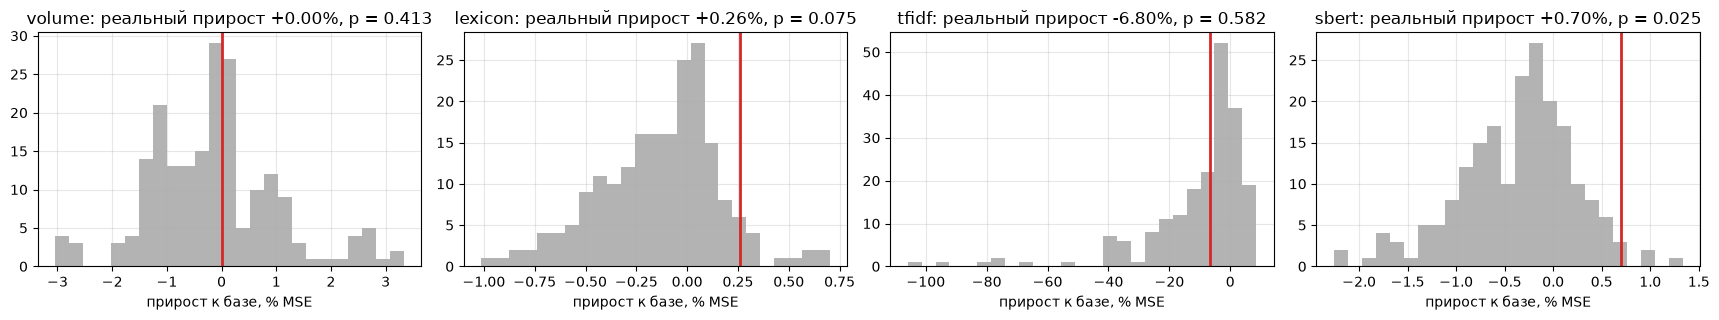

In [25]:
def placebo(emb, n=N_PLACEBO):
    s = INFO[f"база + {emb}"]
    rng = make_rng(301, list(EMB).index(emb))           # свой генератор: перезапуск ячейки даёт те же сдвиги
    E = EMB[emb].to_numpy()
    def g(Em):
        X = ou_state(Em, gap_days, s["half_life"])
        return gain(y, fit_predict(np.hstack([F_base, X]), y, TV, s["alpha"])[0], P["база"], TE)
    real = g(E)
    shifts = rng.integers(Z_WINDOW, len(E) - Z_WINDOW, size=n)
    fake = np.array([g(np.roll(E, k, axis=0)) for k in shifts])
    return real, fake, (1 + np.sum(fake >= real)) / (n + 1)

PLACEBO = {}
fig, axs = plt.subplots(1, len(EMB), figsize=(4.3 * len(EMB), 3.3))
for ax, emb in zip(np.atleast_1d(axs), EMB):
    real, fake, p = placebo(emb)
    PLACEBO[emb] = p
    ax.hist(fake, bins=25, color="0.7"); ax.axvline(real, color="C3", lw=2)
    ax.set_title(f"{emb}: реальный прирост {real:+.2f}%, p = {p:.3f}"); ax.set_xlabel("прирост к базе, % MSE")
plt.tight_layout(); plt.show()

**Как читать.** Серая гистограмма — что получается при случайной связи, красная линия — реальный результат.
Линия правее почти всей серой массы ($p<0.05$) — связь настоящая. Внутри массы — совпадение.
Обратите внимание на ширину серой массы: она показывает, какие «приросты» бывают просто от шума.

## 5.7. По годам: устойчив ли результат?

Тест в 2020–2023 включает пандемию — один необычный период может решить всё. Поэтому для каждого года $Y$:
обучаем базу и «базу + новости» на **всех данных до** 1 января $Y$, предсказываем год $Y$ и считаем прирост
(схема «расширяющегося окна», walk-forward). Хороший результат — прирост положителен **в большинстве лет**.

Оговорка: $h$ и штраф взяты из подбора на валидации (2017–2019), так что для этих лет есть небольшая утечка.

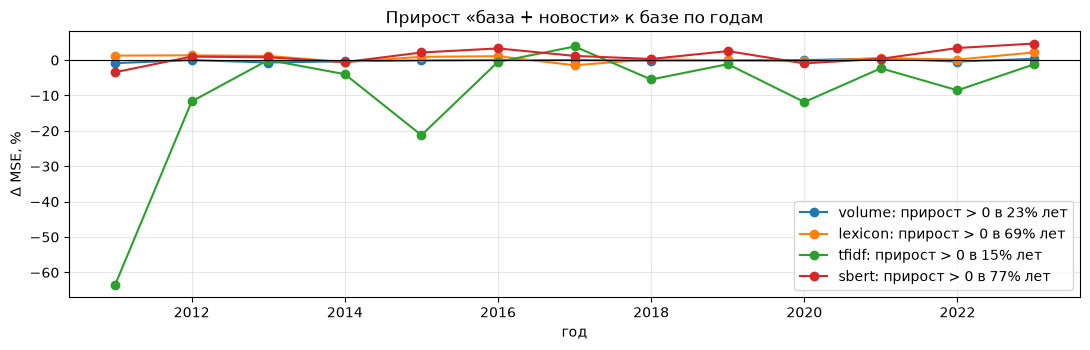

In [26]:
def walk_forward(emb, first_year=2011):
    s = INFO[f"база + {emb}"]
    F_new = np.hstack([F_base, state(emb, s["half_life"])])
    out = {}
    for Y in range(first_year, dates[-1].year + 1):
        fit_m = np.asarray(dates < f"{Y}-01-01") & ok
        te = np.asarray(dates.year == Y) & ok
        if te.sum() < 50:
            continue
        pb = fit_predict(F_base, y, fit_m, INFO["база"]["alpha"])[0]
        pn = fit_predict(F_new, y, fit_m, s["alpha"])[0]
        out[Y] = gain(y, pn, pb, te)
    return pd.Series(out)

WF = {}
fig, ax = plt.subplots()
for emb in EMB:
    WF[emb] = g_wf = walk_forward(emb)
    ax.plot(g_wf.index, g_wf.values, marker="o", label=f"{emb}: прирост > 0 в {(g_wf > 0).mean():.0%} лет")
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Прирост «база + новости» к базе по годам"); ax.set_xlabel("год"); ax.set_ylabel("Δ MSE, %"); ax.legend()
plt.tight_layout(); plt.show()

## 5.8. Форма памяти: действительно ли влияние затухает экспоненциально?

Это прямая проверка самой идеи OU. Не предполагая никакой формы памяти, оцениваем свободную регрессию

$$
y_t=\text{база}_t+h_0\varepsilon_t+h_1\varepsilon_{t-1}+\dots+h_{20}\varepsilon_{t-20}
$$

и рисуем коэффициенты $h_k$ («импульсный отклик»). Если модель с баком верна, $h_k$ должны **плавно спадать**
(красная кривая — лучшая экспонента). Возможные картины:

* плавный спад — память есть, идея бака оправдана;
* всплеск на $k=0$ и дальше ноль — памяти нет, достаточно $\lambda=0$;
* шум вокруг нуля — сигнала нет.

Серая полоса — 95%-интервал с поправкой Ньюи–Уэста. Используем train+val, тест не трогаем.

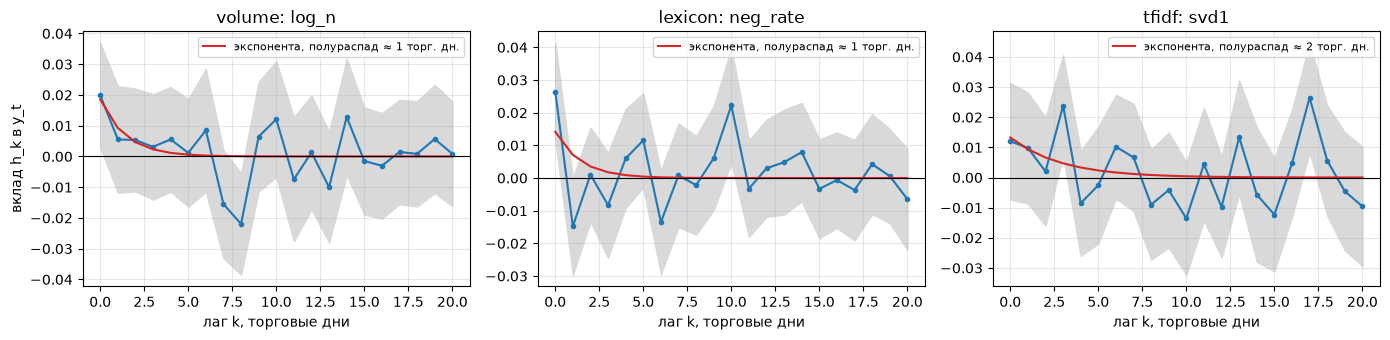

In [27]:
K = 20
IR = [("volume", "log_n"), ("lexicon", "neg_rate"), ("tfidf", "svd1")]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5), sharex=True)
for ax, (emb, c) in zip(axs, IR):
    f = EMB[emb][c].to_numpy()
    L = np.column_stack([np.r_[np.full(k, np.nan), f[:len(f) - k]] for k in range(K + 1)])
    use = TV & np.isfinite(L).all(axis=1)
    beta, se = ols_hac(np.hstack([F_base[use], L[use]]), y[use], lags=K)
    hk, sk = beta[1 + F_base.shape[1]:], se[1 + F_base.shape[1]:]
    ks = np.arange(K + 1)
    ax.fill_between(ks, hk - 1.96 * sk, hk + 1.96 * sk, color="0.85")
    ax.plot(ks, hk, marker=".")
    fits = [(np.sum((hk - (b @ hk) / (b @ b) * b) ** 2), hh, (b @ hk) / (b @ b))
            for hh in (1, 2, 3, 5, 7, 14) for b in [0.5 ** (ks / hh)]]
    _, hh, amp = min(fits, key=lambda t: t[0])
    ax.plot(ks, amp * 0.5 ** (ks / hh), color="C3", label=f"экспонента, полураспад ≈ {hh} торг. дн.")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"{emb}: {c}"); ax.set_xlabel("лаг k, торговые дни"); ax.legend(fontsize=8)
axs[0].set_ylabel("вклад h_k в y_t")
plt.tight_layout(); plt.show()

## 5.9. Какие компоненты новостей работают?

Берём лучший по валидации эмбеддинг с выбранной памятью и оцениваем обычную регрессию (без штрафа) «база + бак» на
train+val с ошибками Ньюи–Уэста. Признаки стандартизованы, поэтому коэффициенты сравнимы: это изменение $y_t$ при
изменении признака на одно стандартное отклонение. $|t|>2$ — коэффициент примерно значим на уровне 5%.
Для тем TF-IDF рядом показаны их главные слова — так видно, *о чём* новости, которые связаны с волатильностью.

In [28]:
s = INFO[f"база + {best_emb}"]
names = BASE_COLS + [f"x: {c}" for c in EMB[best_emb].columns]
F_b = np.hstack([F_base, state(best_emb, s["half_life"])])
Zs = (F_b - F_b[TV].mean(0)) / F_b[TV].std(0)
beta, se = ols_hac(Zs[TV], y[TV], lags=10)
coef = pd.DataFrame({"коэффициент": beta[1:], "ст. ошибка (HAC)": se[1:]}, index=names)
coef["t"] = coef["коэффициент"] / coef["ст. ошибка (HAC)"]
coef["главные слова"] = [TOPIC_WORDS.get(n.replace("x: ", ""), "") if best_emb == "tfidf" else "" for n in names]
print(f"эмбеддинг {best_emb}, память h = {s['half_life']} дн.")
display(coef.round(4))

эмбеддинг tfidf, память h = 60 дн.


,коэффициент,ст. ошибка (HAC),t,главные слова
har1,0.0746,0.0154,4.8489,
har5,0.0920,0.0222,4.1480,
har22,-0.0564,0.0189,-2.9756,
log_vix,0.3730,0.0236,15.7806,
log_abs_gap,0.0576,0.0090,6.3951,
x: svd1,0.0040,0.0109,0.3653,"reported, profit, funds, credit, google, stake"
x: svd2,0.0294,0.0175,1.6841,"reported, reuters, street journal, reuters rep..."
x: svd3,0.0396,0.0118,3.3621,"trump, morning agenda, agenda, donald trump, r..."
x: svd4,-0.0028,0.0111,-0.2513,"recent commercial, commercial real, transactio..."
x: svd5,-0.0415,0.0143,-2.9086,"trump, reuters reported, spill, reuters, donal..."


**Как читать.** У признаков базы $t$ обычно большие — так и должно быть. Для новостных компонент смотрим, есть ли
хоть одна с $|t|>2$ и осмыслен ли её знак (например, «больше негатива — шире размах»). Помните о множественных
сравнениях: среди 8 компонент одна может оказаться «значимой» случайно.

**Итог раздела 5:** теперь известно, добавляют ли новости что-то к базе, устойчиво ли это и какая память им нужна.
Дальше — несколько дополнительных экспериментов, которые помогают понять *почему* результат такой.

---
# 6. Дополнительные эксперименты

Каждый эксперимент меняет **одну** деталь и сравнивает результат с основной постановкой. Чтобы не повторять код,
используем одну функцию `compare`: для ряда $y$, базы и новостей она сама выбирает $h$ и штраф на валидации
и возвращает прирост к базе на валидации и тесте и p-value Кларка–Уэста.

**Какие эмбеддинги участвуют.** Лучший по валидации эмбеддинг не обязательно лучший на тесте (сравните столбцы
`R² val` и `R² test` в разделе 5.4). Поэтому эксперименты считаем сразу для нескольких: лучшего по валидации, `lexicon`
(самый простой и понятный) и `sbert`, если он включён.

In [29]:
def compare(yv, Fb, E, okv, gaps=None):
    # база vs база + бак(E) на одном ряду: подбор на val, прирост и CW на тесте
    gaps = gap_days if gaps is None else gaps
    tv, te = (masks["train"] | masks["val"]) & okv, masks["test"] & okv
    sb = select(lambda h: Fb, yv, okv, half_lives=[0])
    pb = fit_predict(Fb, yv, tv, sb["alpha"])[0]
    make = lambda h: np.hstack([Fb, ou_state(E, gaps, h)])
    sn = select(make, yv, okv)
    pn = fit_predict(make(sn["half_life"]), yv, tv, sn["alpha"])[0]
    return {"h": sn["half_life"], "Δ R² val": sn["R² val"] - sb["R² val"],
            "Δ MSE test, %": gain(yv, pn, pb, te), "CW p": clark_west(yv[te], pb[te], pn[te])[1]}

EXP_EMBS = list(dict.fromkeys([best_emb, "lexicon"] + (["sbert"] if "sbert" in EMB else [])))
print("эмбеддинги в экспериментах раздела 6:", EXP_EMBS, f"(лучший по валидации: {best_emb})")

эмбеддинги в экспериментах раздела 6: ['tfidf', 'lexicon', 'sbert'] (лучший по валидации: tfidf)


## 6.1. Нужны ли календарные $\Delta t$?

В разделе 3 мы сказали, что за выходные бак должен забывать больше. Проверим, важно ли это на практике: сравним
честные календарные паузы с упрощением «каждый шаг = 1 день».

In [30]:
rows = []
for emb in EXP_EMBS:
    E = EMB[emb].to_numpy()
    rows.append({"эмбеддинг": emb, "шаг времени": "календарные дни", **compare(y, F_base, E, ok)})
    rows.append({"эмбеддинг": emb, "шаг времени": "все шаги = 1", **compare(y, F_base, E, ok, gaps=np.ones(len(dates)))})
display(pd.DataFrame(rows).set_index(["эмбеддинг", "шаг времени"]).round(4))

h  Δ R² val  Δ MSE test, %    CW p
эмбеддинг шаг времени                                         
tfidf     календарные дни  60    0.0050        -6.8038  0.9977
          все шаги = 1     60    0.0055        -7.5835  0.9956
lexicon   календарные дни   0   -0.0022         0.2599  0.0515
          все шаги = 1      0   -0.0022         0.2599  0.0515
sbert     календарные дни   0    0.0044         0.6996  0.0067
          все шаги = 1      0    0.0044         0.6996  0.0067

**Как читать.** Если разницы нет, то при выбранной памяти выходные почти не важны (например, при $h=0$ памяти нет
вообще, и $\Delta t$ ни на что не влияет). Если календарный вариант лучше — модель OU с правильной дискретизацией
оправдана и на практике.

## 6.2. Как быстро новости «устаревают»?

Используем новости не сегодняшнего утра, а **$k$ дней назад** ($k=0,1,2,5,10$). Если прирост пропадает уже при
$k=1$, рынок усваивает информацию из новостей в течение одного дня. Если держится — у новостей есть долгая память
(и именно её должен ловить бак).

h  Δ R² val  Δ MSE test, %    CW p
эмбеддинг задержка k                                     
tfidf     0           60    0.0050        -6.8038  0.9977
          1           60    0.0041        -6.4945  0.9981
          2           60    0.0035        -6.6810  0.9971
          5            5    0.0044        -5.4458  0.9976
          10           7    0.0037        -5.2956  0.9982
lexicon   0            0   -0.0022         0.2599  0.0515
          1            0   -0.0009        -0.3572  0.9271
          2            0   -0.0024        -0.4586  0.9844
          5            0    0.0012        -0.8313  0.8674
          10           0   -0.0013        -0.1366  0.3016
sbert     0            0    0.0044         0.6996  0.0067
          1            2    0.0003         0.0150  0.1760
          2            3   -0.0001         0.6159  0.0220
          5            1    0.0036        -0.9025  0.3409
          10           1   -0.0023        -1.0863  0.9456

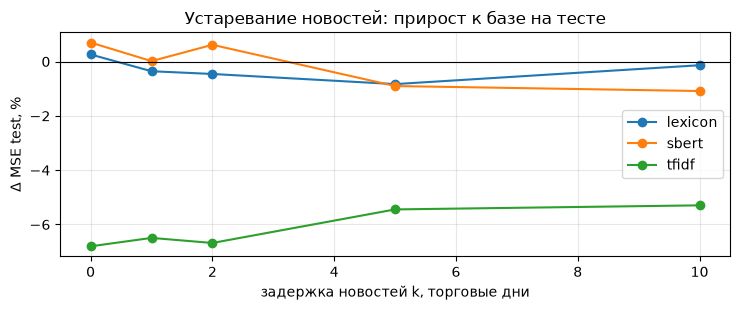

In [31]:
def lagged(E, kk):
    return np.vstack([np.zeros((kk, E.shape[1])), E[:len(E) - kk]]) if kk else E

rows = []
for emb in EXP_EMBS:
    E = EMB[emb].to_numpy()
    for kk in (0, 1, 2, 5, 10):
        rows.append({"эмбеддинг": emb, "задержка k": kk, **compare(y, F_base, lagged(E, kk), ok)})
exp_lag = pd.DataFrame(rows)
display(exp_lag.set_index(["эмбеддинг", "задержка k"]).round(4))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
for emb, g_ in exp_lag.groupby("эмбеддинг"):
    ax.plot(g_["задержка k"], g_["Δ MSE test, %"], marker="o", label=emb)
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("задержка новостей k, торговые дни"); ax.set_ylabel("Δ MSE test, %")
ax.set_title("Устаревание новостей: прирост к базе на тесте"); ax.legend()
plt.tight_layout(); plt.show()

## 6.3. Сколько тем нужно TF-IDF?

Размерность $d$ — компромисс: мало тем — теряем информацию, много — растёт переобучение. Пересчитываем TF-IDF+SVD
с $d=2,4,8,16,32$ (каждый раз обучая SVD только на train) и смотрим на прирост на валидации и тесте.

In [32]:
rows = []
for d in (2, 4, 8, 16, 32):
    E_d = past_zscore(tfidf_features(d)[0]).to_numpy()
    rows.append({"тем d": d, **compare(y, F_base, E_d, ok)})
exp_dim = pd.DataFrame(rows).set_index("тем d")
display(exp_dim.round(4))

,h,Δ R² val,"Δ MSE test, %",CW p
тем d,,,,
2,60,-0.0025,-1.6988,0.9986
4,2,0.0026,-3.1212,1.0000
8,60,0.0050,-6.8038,0.9977
16,2,0.0007,-6.5003,0.9932
32,3,0.0006,-9.8376,0.9971


**Как читать.** Если прирост на валидации растёт с $d$, а на тесте нет — это переобучение: больше тем дают больше
возможностей подогнаться под шум. Оптимальное $d$ — там, где тест перестаёт улучшаться.

## 6.4. Темы или рубрики?

Проверяем опасение из раздела 2.3: не ловит ли TF-IDF регулярные рубрики вместо событий. Рубрику узнаём по
**повторяющемуся заголовку**: берём заголовок, убираем цифры и знаки, и если такой же заголовок (или его часть до
двоеточия, например `Morning Agenda: …`, `Your Friday Briefing: …`) встречается на train не меньше 20 раз — считаем
статью рубрикой. Затем строим TF-IDF без рубрик и сравниваем.

In [33]:
def template_key(headlines):
    h = headlines.str.lower()
    prefix = h.str.split(r"[:|]", n=1, regex=True).str[0]
    norm = lambda s: s.str.replace(r"[\d\W_]+", " ", regex=True).str.strip()
    return norm(h), norm(prefix), h.str.contains(r"[:|]", regex=True)

full_key, pref_key, has_sep = template_key(pre["headline"])
in_train = (pre["trading_date"] <= TRAIN_END).to_numpy()
cnt_full = full_key[in_train].value_counts()
cnt_pref = pref_key[in_train & has_sep.to_numpy()].value_counts()
templ_full = set(cnt_full[cnt_full >= 20].index)
templ_pref = set(cnt_pref[cnt_pref >= 20].index)
is_template = full_key.isin(templ_full) | (has_sep & pref_key.isin(templ_pref))
print(f"статей-рубрик: {is_template.sum():,} из {len(pre):,} ({is_template.mean():.1%})")
print("самые частые рубрики на train:")
top = pd.concat([cnt_full[cnt_full >= 20], cnt_pref[cnt_pref >= 20]]).sort_values(ascending=False).head(12)
display(top.to_frame("статей на train"))

clean = pre[~is_template.to_numpy()]
text_clean = article_text(clean).groupby(clean["trading_date"]).agg("\n".join).reindex(dates).fillna("")
raw_clean, vec_c, svd_c = tfidf_features(D_TFIDF, texts=text_clean)
terms_c = vec_c.get_feature_names_out()
print("темы TF-IDF без рубрик:")
for i, c in enumerate(svd_c.components_[:4]):
    print(f"  svd{i + 1}: " + ", ".join(terms_c[np.argsort(c)[::-1][:6]]))

exp_tmpl = pd.DataFrame([
    {"TF-IDF": "все утренние статьи", **compare(y, F_base, EMB["tfidf"].to_numpy(), ok)},
    {"TF-IDF": "без рубрик", **compare(y, F_base, past_zscore(raw_clean).to_numpy(), ok)},
]).set_index("TF-IDF")
display(exp_tmpl.round(4))

статей-рубрик: 4,103 из 139,095 (2.9%)
самые частые рубрики на train:


,статей на train
headline,
morning agenda,585
daily report,454
morning take out,417
the breakfast meeting,164
news from the advertising industry,153
this week in small business,139
what we re reading,105
thursday reading,99
tuesday reading,97


темы TF-IDF без рубрик:
  svd1: reported, profit, funds, credit, bid, google
  svd2: reported, reuters, street journal, reuters reported, journal, bloomberg news
  svd3: trump, donald trump, donald, clinton, hillary clinton, hillary
  svd4: trump, donald trump, donald, madoff, reuters reported, reuters


,h,Δ R² val,"Δ MSE test, %",CW p
TF-IDF,,,,
все утренние статьи,60,0.005,-6.8038,0.9977
без рубрик,1,0.004,-2.5361,0.7997


**Как читать.** Если без рубрик темы стали осмысленнее (события, компании, макроэкономика вместо названий рубрик),
а прирост на тесте вырос или хотя бы перестал быть сильно отрицательным, — рубрики действительно мешали. Это общий урок:
у текстовых признаков, помимо содержания, есть «формат», и он может меняться во времени сам по себе.

## 6.5. Спокойный и нервный рынок

Возможно, новости важны не всегда, а только в турбулентные периоды. Делим тестовые дни на три группы по вчерашнему
VIX (границы — терцили VIX на train+val, чтобы не подглядывать в тест) и считаем прирост к базе отдельно в каждой.

In [34]:
q1, q2 = np.nanquantile(M["log_vix"].to_numpy()[TV], [1 / 3, 2 / 3])
v = M["log_vix"].to_numpy()
rows = []
for emb in EXP_EMBS:
    p_e = P[f"база + {emb}"]
    for name, m in (("спокойный (низкий VIX)", v <= q1), ("средний", (v > q1) & (v <= q2)),
                    ("нервный (высокий VIX)", v > q2)):
        te = TE & m
        rows.append({"эмбеддинг": emb, "режим рынка": name, "дней в тесте": int(te.sum()),
                     "Δ MSE vs база, %": gain(y, p_e, P["база"], te) if te.sum() > 20 else np.nan,
                     "CW p": clark_west(y[te], P["база"][te], p_e[te])[1] if te.sum() > 20 else np.nan})
display(pd.DataFrame(rows).set_index(["эмбеддинг", "режим рынка"]).round(4))

дней в тесте  Δ MSE vs база, %    CW p
эмбеддинг режим рынка                                                   
tfidf     спокойный (низкий VIX)            17               NaN     NaN
          средний                          161          -10.6102  0.9998
          нервный (высокий VIX)            659           -5.7402  0.9431
lexicon   спокойный (низкий VIX)            17               NaN     NaN
          средний                          161            1.1386  0.0156
          нервный (высокий VIX)            659           -0.0788  0.2257
sbert     спокойный (низкий VIX)            17               NaN     NaN
          средний                          161           -1.0829  0.4829
          нервный (высокий VIX)            659            1.1750  0.0010

**Как читать.** Если прирост сосредоточен в нервных днях, новости полезны именно тогда, когда рынок реагирует на
события, — это содержательный вывод для курсовой, даже если в среднем прирост маленький. Учтите, что в каждой группе
дней втрое меньше, и p-value становятся менее надёжными.

## 6.6. Другие цели и другие инструменты

Сработает ли то же самое

* на **другой мере волатильности** — $\log|r^{oc}_t|$ (модуль доходности сессии, более шумная мера, чем размах);
* на **знаке** доходности сессии $r^{oc}_t$, где по теории эффективного рынка ждём пустоту;
* на **других ETF**: Nasdaq-100 (QQQ), технологии (XLK), финансы (XLF), энергетика (XLE)?

Для доходности база — вчерашняя доходность сессии и ночной гэп со знаком. Строк много, поэтому p-значения обязательно
смотрим **с поправкой Холма** (по всей таблице сразу).

h  Δ R² val  Δ MSE test, %    CW p  \
инструмент цель              эмбеддинг                                        
SPY        log размаха       tfidf      60    0.0050        -6.8038  0.9977   
                             lexicon     0   -0.0022         0.2599  0.0515   
                             sbert       0    0.0044         0.6996  0.0067   
           log |r сессии|    tfidf       3    0.0091        -0.8386  0.6304   
                             lexicon     0   -0.0001         0.0265  0.2620   
                             sbert       0    0.0017         0.1669  0.1392   
           доходность сессии tfidf       0    0.0007        -0.2380  0.8736   
                             lexicon     7    0.0027        -0.2107  0.8178   
                             sbert       5   -0.0004        -0.1014  0.6620   
QQQ        log размаха       tfidf       0    0.0022         0.5568  0.0156   
                             lexicon     0   -0.0008         0.2738  0.0480   
                             sbert      60    0.0033         1.7889  0.0002   
           log |r сессии|    tfidf       0   -0.0025         0.0691  0.2110   
                             lexicon     0    0.0002         0.1607  0.1202   
                             sbert      60    0.0005         0.5662  0.0130   
           доходность сессии tfidf       0   -0.0006        -0.2758  0.8588   
                             lexicon     7    0.0018        -0.0707  0.6017   
                             sbert      60   -0.0009         0.2784  0.0235   
XLK        log размаха       tfidf       0    0.0019         0.5250  0.0186   
                             lexicon     0    0.0003         0.3546  0.0366   
                             sbert       0    0.0039         1.9034  0.0001   
           log |r сессии|    tfidf       0   -0.0005        -0.3106  0.7566   
                             lexicon     7   -0.0026         0.0437  0.2894   
                             sbert       0   -0.0021         0.2805  0.0433   
           доходность сессии tfidf      60   -0.0003         0.0712  0.1583   
                             lexicon     7    0.0011        -0.0849  0.7242   
                             sbert      60    0.0005         0.2658  0.0347   
XLF        log размаха       tfidf       1    0.0104        -0.1490  0.2429   
                             lexicon    60    0.0041        -0.4535  0.5827   
                             sbert       0    0.0110         1.1096  0.0023   
           log |r сессии|    tfidf      60    0.0030        -0.3761  0.6502   
                             lexicon     0    0.0026        -0.2355  0.6738   
                             sbert       0    0.0072        -0.2742  0.3206   
           доходность сессии tfidf      60   -0.0021        -0.0387  0.6779   
                             lexicon     7    0.0002        -0.3285  0.6687   
                             sbert       2   -0.0027        -0.2303  0.7877   
XLE        log размаха       tfidf       1    0.0037        -1.5597  0.9283   
                             lexicon     1    0.0004        -0.0852  0.2250   
                             sbert       0    0.0000         1.1713  0.0084   
           log |r сессии|    tfidf       1    0.0046        -0.6098  0.6278   
                             lexicon    60   -0.0005        -0.4867  0.9060   
                             sbert       0    0.0007        -0.3506  0.5085   
           доходность сессии tfidf       5   -0.0001         0.0687  0.2229   
                             lexicon    14   -0.0004        -0.0299  0.6435   
                             sbert       0   -0.0032        -0.0211  0.4221   

                                        CW p (Холм)  
инструмент цель              эмбеддинг               
SPY        log размаха       tfidf           1.0000  
                             lexicon         1.0000  
                             sbert           0.2798  
           log |r сессии|    tfidf           1.0000  
   

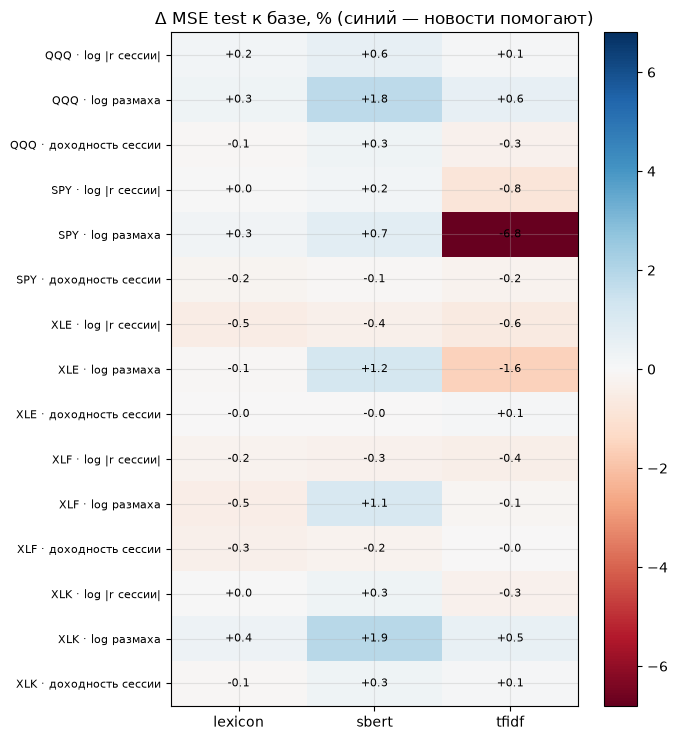

In [35]:
rows = []
warm = np.arange(len(dates)) >= WARMUP
TARGETS6 = (("log размаха", "y_range", BASE_COLS),
            ("log |r сессии|", "y_absoc", BASE_COLS),
            ("доходность сессии", "r_oc", ["r_oc_lag", "gap"]))
for tk in OTHER_TICKERS:
    if tk not in set(prices["ticker"]):
        continue
    Mk = market_table(tk)
    for target, col, cols in TARGETS6:
        yk = Mk[col].to_numpy()
        Fk = Mk[cols].to_numpy()
        okk = np.isfinite(yk) & np.isfinite(Fk).all(axis=1) & warm
        for emb in EXP_EMBS:
            rows.append({"инструмент": tk, "цель": target, "эмбеддинг": emb,
                         **compare(yk, Fk, EMB[emb].to_numpy(), okk)})
other = pd.DataFrame(rows)
other["CW p (Холм)"] = holm(other["CW p"])
display(other.set_index(["инструмент", "цель", "эмбеддинг"]).round(4))

pivot = other.pivot_table(index=["инструмент", "цель"], columns="эмбеддинг", values="Δ MSE test, %")
fig, ax = plt.subplots(figsize=(7, 0.4 * len(pivot) + 1.5))
lim = np.nanmax(np.abs(pivot.values)) or 1
im = ax.imshow(pivot.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
ax.set_yticks(range(len(pivot))); ax.set_yticklabels([f"{a} · {b}" for a, b in pivot.index], fontsize=8)
ax.set_xticks(range(pivot.shape[1])); ax.set_xticklabels(pivot.columns)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:+.1f}", ha="center", va="center", fontsize=8)
ax.set_title("Δ MSE test к базе, % (синий — новости помогают)"); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

**Как читать.** Устойчивый эффект должен повторяться на нескольких инструментах (они сильно коррелированы, но не
одинаковы) и на обеих мерах волатильности: в тепловой карте это синий столбец сверху донизу для строк волатильности.
На доходности со знаком ждём около нуля или красное. Если «значимым» оказался один ETF из пяти — после поправки Холма
это обычно исчезает.

## 6.7. Только финансовые новости или все?

Во всей тетрадке мы брали только финансовые статьи (около трети потока). Но волатильность часто начинается с событий,
которые в бизнес-раздел попадают не сразу: войны, выборы, теракты, эпидемии. Проверяем, что дают остальные рубрики.
Культура, спорт и прочие развлекательные разделы уже убраны при сборке датасета, так что «все новости» здесь — это
мир, США, политика, Нью-Йорк, наука, здоровье, технологии, мнения и т.п.

Для каждого эмбеддинга сравниваем три варианта $\varepsilon_t$:

| вариант | что подаём в бак | на какой вопрос отвечает |
|---|---|---|
| только финансовые | как во всей тетрадке | — (точка отсчёта) |
| все новости вместе | один поток из всех утренних статей | лучше ли один общий поток, чем финансовый? |
| финансовые + нефинансовые (2 канала) | признаки финансовых **и отдельно** признаки остальных статей | добавляют ли остальные новости что-то **сверх** финансовых? |

Чего можно ожидать. Плюс от всех новостей: больше информации о событиях. Минус: финансовый сигнал «разбавляется».
Например, доля негативных слов во всех текстах меньше говорит о рынке, чем в финансовых: негатив в криминальной хронике
к волатильности отношения не имеет. Вариант «2 канала» не разбавляет, а добавляет — но и параметров у него вдвое больше.

SBERT здесь считается только при `SBERT_ALL_NEWS = True`: нефинансовых статей примерно вдвое больше, чем финансовых.
Первый расчёт идёт на GPU, если CUDA доступна; потом векторы читаются из кэша.

утренних статей в день: финансовых 36.1, остальных 96.6, всего 132.7
самые частые рубрики среди нефинансовых утренних статей:


,% статей
section,
U.S.,25.2
World,20.2
Opinion,17.4
New York,15.3
Blogs,5.0
Education,2.9
Health,2.8
Science,2.5
Real Estate,2.1


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

SBERT encode: 372,840 статей на cuda (NVIDIA GeForce RTX 2060)


Batches:   0%|          | 0/1457 [00:00<?, ?it/s]

чисел в ε_t   h  Δ R² val  \
эмбеддинг новости                                                           
volume    только финансовые                               1  60   -0.0000   
          все новости вместе                              1  30    0.0004   
          финансовые + нефинансовые (2 канала)            2  60    0.0008   
lexicon   только финансовые                               3   0   -0.0022   
          все новости вместе                              3   0   -0.0000   
          финансовые + нефинансовые (2 канала)            6   0    0.0000   
tfidf     только финансовые                               8  60    0.0050   
          все новости вместе                              8   1    0.0027   
          финансовые + нефинансовые (2 канала)           16  60    0.0020   
sbert     только финансовые                               8   0    0.0044   
          все новости вместе                              8   1   -0.0009   
          финансовые + нефинансовые (2 канала)           16   0   -0.0007   

                                                Δ MSE test, %    CW p  \
эмбеддинг новости                                                       
volume    только финансовые                            0.0009  0.0001   
          все новости вместе                           0.4677  0.0000   
          финансовые + нефинансовые (2 канала)         0.2878  0.0762   
lexicon   только финансовые                            0.2599  0.0515   
          все новости вместе                           0.3815  0.0365   
          финансовые + нефинансовые (2 канала)         0.7044  0.0076   
tfidf     только финансовые                           -6.8038  0.9977   
          все новости вместе                           1.2162  0.0013   
          финансовые + нефинансовые (2 канала)        -5.1374  0.9996   
sbert     только финансовые                            0.6996  0.0067   
          все новости вместе                          -0.7723  0.3550   
          финансовые + нефинансовые (2 канала)         1.3048  0.0011   

                                                CW p (Холм)  
эмбеддинг новости                                            
volume    только финансовые                          0.0009  
          все новости вместе                         0.0005  
          финансовые + нефинансовые (2 канала)       0.3046  
lexicon   только финансовые                          0.2577  
          все новости вместе                         0.2190  
          финансовые + нефинансовые (2 канала)       0.0534  
tfidf     только финансовые                          1.0000  
          все новости вместе                         0.0114  
          финансовые + нефинансовые (2 канала)       1.0000  
sbert     только финансовые                          0.0533  
          все новости вместе                         1.0000  
          финансовые + нефинансовые (2 канала)       0.0111

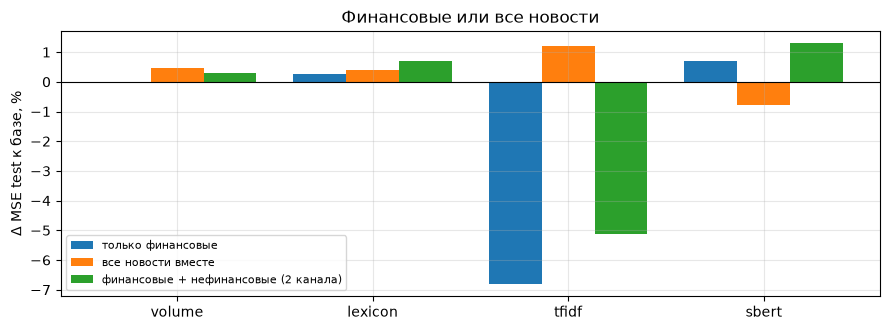

In [36]:
pre_nf = pre_all[~pre_all["is_finance"].to_numpy()]

def day_texts(df):
    return article_text(df).groupby(df["trading_date"]).agg("\n".join).reindex(dates).fillna("")

def day_count(df):
    return df.groupby("trading_date").size().reindex(dates).fillna(0).to_numpy()

text_all, text_nf = day_texts(pre_all), day_texts(pre_nf)
n_all, n_nf = day_count(pre_all), day_count(pre_nf)
print(f"утренних статей в день: финансовых {n_pre.mean():.1f}, остальных {n_nf.mean():.1f}, всего {n_all.mean():.1f}")
print("самые частые рубрики среди нефинансовых утренних статей:")
display((pre_nf["section"].replace("", "(без рубрики)").value_counts(normalize=True).head(10) * 100)
        .round(1).to_frame("% статей"))

def variants(kind):
    # три варианта ε_t для одного типа эмбеддинга (сырые признаки → очистка z-score)
    if kind == "volume":
        f = lambda n: pd.DataFrame({"log_n": np.log1p(n / gap_days)}, index=dates)
        all_, nf = f(n_all), f(n_nf)
    elif kind == "lexicon":
        all_, nf = lexicon_features(text_all), lexicon_features(text_nf)
    elif kind == "tfidf":
        all_, nf = tfidf_features(D_TFIDF, texts=text_all)[0], tfidf_features(D_TFIDF, texts=text_nf)[0]
    elif kind == "sbert":
        if "nf" not in SBERT_EMB:
            SBERT_EMB["nf"] = sbert_encode(article_text(pre_nf).to_numpy())
        both = pd.concat([pre, pre_nf])
        all_ = sbert_daily(both, np.vstack([SBERT_EMB["fin"], SBERT_EMB["nf"]]))[0]
        nf = sbert_daily(pre_nf, SBERT_EMB["nf"])[0]
    fin = EMB[kind].to_numpy()
    return {"только финансовые": fin,
            "все новости вместе": past_zscore(all_).to_numpy(),
            "финансовые + нефинансовые (2 канала)": np.hstack([fin, past_zscore(nf).to_numpy()])}

kinds = ["volume", "lexicon", "tfidf"]
if "sbert" in EMB:
    if SBERT_ALL_NEWS:
        kinds.append("sbert")
    else:
        print("SBERT в этом эксперименте пропущен (SBERT_ALL_NEWS = False)")

rows = []
for kind in kinds:
    for name, E in variants(kind).items():
        rows.append({"эмбеддинг": kind, "новости": name, "чисел в ε_t": E.shape[1], **compare(y, F_base, E, ok)})
exp_all = pd.DataFrame(rows)
exp_all["CW p (Холм)"] = holm(exp_all["CW p"])
display(exp_all.set_index(["эмбеддинг", "новости"]).round(4))

fig, ax = plt.subplots(figsize=(9, 3.4))
order = ["только финансовые", "все новости вместе", "финансовые + нефинансовые (2 канала)"]
w = 0.27
for i, name in enumerate(order):
    vals = exp_all[exp_all["новости"] == name].set_index("эмбеддинг").reindex(kinds)["Δ MSE test, %"]
    ax.bar(np.arange(len(kinds)) + (i - 1) * w, vals.values, width=w, label=name)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(kinds))); ax.set_xticklabels(kinds)
ax.set_ylabel("Δ MSE test к базе, %"); ax.set_title("Финансовые или все новости"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Как читать.**

* «все новости вместе» **лучше** «только финансовых» — фильтр отбрасывал полезное, и основную постановку стоит
  перестроить на все рубрики;
* «все вместе» **хуже**, а «2 канала» не лучше «только финансовых» — нефинансовые новости только разбавляют сигнал,
  и выбор финансового потока оправдан;
* «2 канала» лучше обоих — у остальных новостей есть **своя** информация, но смешивать её с финансовой в одном
  потоке нельзя.

Сравнивайте и валидацию, и тест: у варианта «2 канала» вдвое больше чисел в $\varepsilon_t$, и на валидации он может
выигрывать просто за счёт лишней гибкости.

## 6.8. Ловушка подглядывания: почему только утренние новости

Повторим сравнение для `lexicon`, но возьмём **все новости дня до закрытия** — включая статьи, вышедшие во время
торгов. Формально это «новости дня $t$», но многие из них *описывают* сам день («акции резко упали…»), то есть
содержат ответ.

In [37]:
E_day = past_zscore(lexicon_features(text_day)).to_numpy()
trap = pd.DataFrame([
    {"новости": "до 9:30 (честно)", **compare(y, F_base, EMB["lexicon"].to_numpy(), ok)},
    {"новости": "весь день до закрытия (подглядывание)", **compare(y, F_base, E_day, ok)},
]).set_index("новости")
display(trap.round(4))

,h,Δ R² val,"Δ MSE test, %",CW p
новости,,,,
до 9:30 (честно),0,-0.0022,0.2599,0.0515
весь день до закрытия (подглядывание),0,-0.0035,0.8042,0.0022


**Как читать.** Если вариант «весь день» даёт заметно больший прирост — это не заслуга модели, а утечка ответа
в признаки. Такой результат легко принять за успех; поэтому время новостей и время цели мы развели с самого начала.

---
# 7. Итоги

Собираем все проверки для основной цели (размах сессии SPY) в одну таблицу — отдельно для общей $\lambda$
и для диагональной $A$. Добавка новостей считается **реальной**, только если выполнены все условия сразу:

1. прирост к базе на тесте **заметен** (≥ `MIN_GAIN` = 0.5%) и `CW p (Холм)` < 0.05;
2. плацебо $p$ < 0.05;
3. прирост положителен в большинстве лет (≥ 60%);
4. для содержательных эмбеддингов (`lexicon`, `tfidf`, `sbert`) — прирост больше, чем у контрольного `volume`.

Плацебо и проверка по годам считались для общей $\lambda$; для диагональной $A$ в таблице только тест и CW.

In [38]:
rows = []
for emb in EMB:
    name = f"база + {emb}"
    rows.append({"эмбеддинг": emb, "память": "общая λ", "полураспад h": INFO[name]["half_life"],
                 "Δ MSE test, %": main.loc[name, "Δ MSE vs база, %"],
                 "CW p (Холм)": main.loc[name, "CW p (Холм)"],
                 "плацебо p": PLACEBO[emb],
                 "доля лет с приростом": (WF[emb] > 0).mean()})
summary = pd.DataFrame(rows).set_index("эмбеддинг")
vol_gain = summary.loc["volume", "Δ MSE test, %"]

def verdict(r):
    if r["Δ MSE test, %"] < MIN_GAIN or r["CW p (Холм)"] >= 0.05:
        if r["Δ MSE test, %"] > 0 and r["CW p (Холм)"] < 0.05:
            return "значимо, но слишком мало"
        return "новости ничего не добавляют"
    if r["плацебо p"] >= 0.05 or r["доля лет с приростом"] < 0.6:
        return "слабый / неустойчивый след"
    if r.name != "volume" and r["Δ MSE test, %"] <= vol_gain:
        return "работает объём, а не смысл"
    return "есть устойчивая добавка"

summary["вывод"] = summary.apply(verdict, axis=1)
display(summary.round(4))

diag_rows = []
for emb, dd in DIAG.items():
    p_diag = fit_predict(dd["F"], y, TV, INFO[f"база + {emb}"]["alpha"])[0]
    diag_rows.append({"эмбеддинг": emb, "h_i": dd["h"], "Δ MSE test, %": gain(y, p_diag, P["база"], TE),
                      "CW p": clark_west(y[TE], P["база"][TE], p_diag[TE])[1]})
if diag_rows:
    diag_tab = pd.DataFrame(diag_rows).set_index("эмбеддинг")
    diag_tab["CW p (Холм)"] = holm(diag_tab["CW p"])
    print("диагональная A:")
    display(diag_tab.round(4))

print(f"\nБаза без новостей на тесте: R² = {r2_vs(y, P['база'], TE, ref):.3f}  "
      f"(HAR: {r2_vs(y, P['HAR'], TE, ref):.3f})")
good = summary.index[summary["вывод"] == "есть устойчивая добавка"].tolist()
if good:
    print("Устойчивая добавка новостей к базе (общая λ):", ", ".join(good))
else:
    print("Ни один эмбеддинг с общей λ не дал устойчивой добавки к базе (HAR + VIX + гэп).")
print(f"Ловушка подглядывания: прирост «до 9:30» = {trap.iloc[0]['Δ MSE test, %']:+.2f}%, "
      f"«весь день» = {trap.iloc[1]['Δ MSE test, %']:+.2f}%")

,память,полураспад h,"Δ MSE test, %",CW p (Холм),плацебо p,доля лет с приростом,вывод
эмбеддинг,,,,,,,
volume,общая λ,60,0.0009,0.0003,0.4129,0.2308,"значимо, но слишком мало"
lexicon,общая λ,0,0.2599,0.1031,0.0746,0.6923,новости ничего не добавляют
tfidf,общая λ,60,-6.8038,0.9977,0.5821,0.1538,новости ничего не добавляют
sbert,общая λ,0,0.6996,0.0200,0.0249,0.7692,есть устойчивая добавка


диагональная A:


,h_i,"Δ MSE test, %",CW p,CW p (Холм)
эмбеддинг,,,,
lexicon,"[0, 3, 0]",-0.0153,0.1763,0.3525
tfidf,"[2, 60, 60, 1, 60, 30, 0, 7]",-8.3561,0.9984,0.9984
sbert,"[0, 60, 5, 5, 0, 60, 5, 0]",2.1447,0.0000,0.0000



База без новостей на тесте: R² = 0.627  (HAR: 0.595)
Устойчивая добавка новостей к базе (общая λ): sbert
Ловушка подглядывания: прирост «до 9:30» = +0.26%, «весь день» = +0.80%


### Как читать итог

| что видим | что это значит |
|---|---|
| база сильно бьёт `mean`, а новости к ней почти ничего не добавляют | вся предсказуемая часть волатильности уже в истории рынка, VIX и ночном гэпе |
| CW значим, а прирост — тысячные доли процента | статистически «не ноль», практически — ноль |
| `volume` не хуже `lexicon` / `tfidf` | важно, *сколько* пишут, а не *что* |
| лучший на валидации эмбеддинг проваливается на тесте | настройки подогнались под валидацию, или признак «поплыл» со временем (рубрики, 6.4) |
| профиль по $h$ плоский (4.4.3) | точное значение памяти по данным не определяется |
| диагональная $A$ лучше общей $\lambda$, а полная — нет (5.5) | разные компоненты забываются с разной скоростью, но взаимного влияния не видно |
| прирост пропадает при задержке $k=1$ (6.2) | рынок усваивает новости за день |
| прирост есть только в нервные дни (6.5) | новости важны в турбулентность |
| на знаке доходности пусто (6.6) | так и должно быть: направление рынка новостями не предсказать |
| «весь день» в 6.8 сильно лучше «до 9:30» | без контроля времени результат был бы ложным |

**Осторожно с множественными сравнениями.** Мы проверили много вариантов: эмбеддинги, память, инструменты, цели.
Даже без всякого сигнала примерно одна проверка из двадцати даст p < 0.05 случайно. Поэтому смотрим на p с поправкой
Холма и доверяем только тому, что повторяется в разных проверках.

### Что можно сделать дальше

1. **Другие модели эмбеддингов:** FinBERT или более сильные sentence-модели (e5, bge) по отдельным статьям.
2. **Больше рядов вместо больших лет:** общие $A$ и $g$ для всех секторных ETF сразу — сотни наблюдений в день вместо одного.
3. **Ближе к буквальной цене:** $p_t=m_t+\langle g,x_t\rangle$, где $m_t$ — случайное блуждание (постоянная часть цены),
   а $\langle g,x_t\rangle$ — затухающая реакция на новости; оценивается фильтром Калмана.
4. **Внутридневные данные:** реализованная волатильность по 5-минутным ценам — более точная цель, чем дневной размах.

---
# 8. Эксперимент: новости «по датам» или «до 9:30»?

Во всей тетрадке новости для дня $t$ отбирались **по точному времени**: всё, что вышло после закрытия $t-1$ (16:00)
и до открытия $t$ (9:30). Более простая схема, которая не требует времени публикации, — **по календарным датам**:
для прогноза сессии дня $t$ берём все статьи, датированные (по Нью-Йорку) от прошлого торгового дня до дня $t-1$
включительно. В понедельник это пятница, суббота и воскресенье.

```
          день t−1                                  день t
 00:00 ── сессия t−1 ── 16:00 ── вечер ── 00:00 ── утро ── 9:30 ── сессия t ── 16:00
 |────────────── «по датам» ──────────────|
                         |──────────── «до 9:30» ─────────────|
                                                               |── что предсказываем ──|
```

**Обе схемы честные:** ни одна статья не выходит позже открытия дня $t$, а цель — размах сессии $t$ — начинается
только в 9:30. Различаются они тем, *какие* новости попадают в $\varepsilon_t$:

| | «до 9:30» | «по датам» |
|---|---|---|
| вечер $t-1$ (после закрытия) | есть | есть |
| утро дня $t$ (полночь – 9:30) | **есть** | нет — самые свежие новости теряются |
| новости, вышедшие во время сессии $t-1$ | нет — выпадают совсем | **есть** (с опозданием на день) |
| нужно ли точное время публикации | да | **нет** |

**Зачем это проверять.** Если схема «по датам» почти не хуже, точное время не так важно, и выборку можно удлинить
назад — в годы, где у статей есть только дата (2000–2007, 1990-е), и на источники без времени публикации.
Если заметно хуже — главная информация приходит в последние часы перед открытием, и это содержательный вывод.

**Какие модели сравниваем.** Самые сильные из предыдущих разделов: SBERT с общей и с диагональной памятью
(разделы 5.4–5.5), SBERT двумя каналами «финансовые + нефинансовые» и TF-IDF по всем новостям (раздел 6.7),
словарь двумя каналами. Важная оговорка: эти модели выбраны *после* того, как мы видели их результаты на тесте.
Поэтому эксперимент сравнивает **схемы между собой** (относительно), а не подтверждает сам эффект новостей:
для этого нужна отложенная выборка.

Сначала собираем статьи. Для схемы «по датам» нужны и те статьи, что вышли во время торгов; финансовые у нас уже
есть, нефинансовые подгружаем отдельно.

In [ ]:
NY = "America/New_York"

def by_date_key(df):
    # схема «по датам»: статья с датой d (по Нью-Йорку) идёт в первый торговый день строго после d
    d = df["pub_time_utc"].dt.tz_convert(NY).dt.tz_localize(None).dt.normalize().to_numpy()
    idx = np.searchsorted(dates.to_numpy(), d, side="right")
    key = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
    inside = idx < len(dates)
    key[inside] = dates.to_numpy()[idx[inside]]
    return key

# четыре группы статей: финансовые / остальные × до открытия / во время торгов
fin_pre = news[news["pre_open"]]                       # = pre (векторы SBERT уже в кэше)
fin_rest = news[~news["pre_open"]]
nf_pre = pre_all[~pre_all["is_finance"].to_numpy()]    # = pre_nf из 6.7 (векторы SBERT уже в кэше)

try:
    nf_rest = pd.read_parquet(C.PROCESSED_FILES["news"], columns=NEWS_COLS,
                              filters=[("trading_date", ">=", pd.Timestamp(START))])
except Exception:
    nf_rest = pd.read_parquet(C.PROCESSED_FILES["news"], columns=NEWS_COLS)
nf_rest["trading_date"] = pd.to_datetime(nf_rest["trading_date"])
nf_rest = nf_rest[nf_rest["trading_date"].isin(dates) & ~nf_rest["is_finance"]]
pub_nr = nf_rest["pub_time_utc"].dt.tz_convert("UTC").dt.tz_localize(None)
nf_rest = nf_rest[(pub_nr > nf_rest["trading_date"].map(open_utc)).to_numpy()].copy()

GROUPS = {"fin_pre": fin_pre, "fin_rest": fin_rest, "nf_pre": nf_pre, "nf_rest": nf_rest}
SCHEMES = {
    "до 9:30":   {"fin": ["fin_pre"], "nf": ["nf_pre"], "key": lambda df: df["trading_date"]},
    "по датам":  {"fin": ["fin_pre", "fin_rest"], "nf": ["nf_pre", "nf_rest"], "key": by_date_key},
}

# сколько статей в день и насколько схемы пересекаются (финансовые статьи)
k_date_fin_pre = by_date_key(fin_pre)
lost_morning = (k_date_fin_pre != fin_pre["trading_date"]).mean()      # утро дня t: «по датам» отдаст их дню t+1
n_fin_date = pd.concat([k_date_fin_pre, by_date_key(fin_rest)]).dropna().value_counts().reindex(dates).fillna(0)
print(f"финансовых статей в день: «до 9:30» {n_pre.mean():.1f}, «по датам» {n_fin_date.mean():.1f}")
print(f"из утренних статей дня t вышли после полуночи (схема «по датам» их для дня t не видит): {lost_morning:.0%}")
print(f"статей, вышедших во время торгов (в «до 9:30» не используются вообще): "
      f"финансовых {len(fin_rest):,}, остальных {len(nf_rest):,}")

Теперь строим одни и те же признаки по обеим схемам. Код общий: схема задаёт только, **какие группы статей**
берутся и **к какому дню** приписывается статья. Векторы SBERT для статей, вышедших во время торгов, считаются
один раз и кэшируются; для утренних статей берутся из кэша разделов 2.4 и 6.7.

In [ ]:
def scheme_texts(scheme, parts):
    # тексты дня по схеме; статьи склеиваются в исходном порядке датасета (как в разделах 2 и 6.7)
    s = SCHEMES[scheme]
    dfs = [GROUPS[g] for p in parts for g in s[p]]
    txt = pd.concat([article_text(df) for df in dfs]).sort_index(kind="stable")
    key = pd.concat([s["key"](df) for df in dfs]).sort_index(kind="stable")
    ok_k = key.notna().to_numpy()
    return txt[ok_k].groupby(key[ok_k].to_numpy()).agg("\n".join).reindex(dates).fillna("")

def scheme_sbert(scheme, part):
    # среднее векторов статей за день (по схеме) → PCA, обученный на train
    s = SCHEMES[scheme]
    S, n = None, None
    for g in s[part]:
        df = GROUPS[g]
        emb = sbert_encode(article_text(df).to_numpy())
        key = s["key"](df)
        ok_k = key.notna().to_numpy()
        Sg = pd.DataFrame(emb[ok_k]).groupby(key[ok_k].to_numpy()).sum().reindex(dates).fillna(0.0)
        ng = key[ok_k].value_counts().reindex(dates).fillna(0)
        S, n = (Sg, ng) if S is None else (S + Sg, n + ng)
        del emb
    day = S.div(n.replace(0, np.nan), axis=0)
    day = day.fillna(day.loc[tr].mean())
    pca = PCA(n_components=D_TFIDF, svd_solver="full").fit(day.loc[tr])
    return pd.DataFrame(pca.transform(day), index=dates, columns=[f"sbert{i + 1}" for i in range(D_TFIDF)])

z = lambda df: past_zscore(df).to_numpy()
HAS_SBERT = "sbert" in EMB

def model_features(scheme):
    # ε_t для каждой из сравниваемых моделей по одной схеме: {название: (матрица, тип памяти)}
    t_fin, t_nf = scheme_texts(scheme, ["fin"]), scheme_texts(scheme, ["nf"])
    t_all = scheme_texts(scheme, ["fin", "nf"])
    out = {}
    if HAS_SBERT:
        sb_fin = z(scheme_sbert(scheme, "fin"))
        out["SBERT · финансовые · общая λ"] = (sb_fin, "scalar")
        out["SBERT · финансовые · диагональная A"] = (sb_fin, "diag")
        out["SBERT · фин + нефин (2 канала)"] = (np.hstack([sb_fin, z(scheme_sbert(scheme, "nf"))]), "scalar")
    out["TF-IDF · все новости вместе"] = (z(tfidf_features(D_TFIDF, texts=t_all)[0]), "scalar")
    out["словарь · фин + нефин (2 канала)"] = (np.hstack([z(lexicon_features(t_fin)), z(lexicon_features(t_nf))]), "scalar")
    return out

FEATS = {sch: model_features(sch) for sch in SCHEMES}
print("моделей:", len(FEATS["до 9:30"]), "×", len(SCHEMES), "схемы")

Оценка — та же, что в разделе 6: настройки ($h$ и сила штрафа) подбираются на валидации **отдельно для каждой
схемы**, финальная модель обучается на train+val, на тесте считаем прирост к базе и тест Кларка–Уэста.
Для диагональной $A$ после подбора общего $h$ делаем покоординатный спуск, как в разделе 4.4.4.

In [ ]:
def compare_diag(yv, Fb, E, okv, passes=2):
    # как compare(), но память диагональная: свой период полураспада у каждой компоненты (покоординатный спуск)
    trm, vam = masks["train"] & okv, masks["val"] & okv
    tv, te = trm | vam, masks["test"] & okv
    sb = select(lambda h: Fb, yv, okv, half_lives=[0])
    pb = fit_predict(Fb, yv, tv, sb["alpha"])[0]
    sn = select(lambda h: np.hstack([Fb, ou_state(E, gap_days, h)]), yv, okv)
    cache = {}
    def col(j, h):
        if (j, h) not in cache:
            cache[(j, h)] = ou_state(E[:, [j]], gap_days, h)
        return cache[(j, h)]
    F_of = lambda v: np.hstack([Fb] + [col(j, h) for j, h in enumerate(v)])
    val_mse = lambda v: mse(yv, fit_predict(F_of(v), yv, trm, sn["alpha"])[0], vam)
    hl = [sn["half_life"]] * E.shape[1]
    for _ in range(passes):
        for j in range(E.shape[1]):
            sc = {h: val_mse(hl[:j] + [h] + hl[j + 1:]) for h in HALF_LIVES}
            hl[j] = min(sc, key=sc.get)
    r2_val = 1 - val_mse(hl) / np.mean((yv[vam] - yv[trm].mean()) ** 2)
    pn = fit_predict(F_of(hl), yv, tv, sn["alpha"])[0]
    return {"h": hl, "Δ R² val": r2_val - sb["R² val"],
            "Δ MSE test, %": gain(yv, pn, pb, te), "CW p": clark_west(yv[te], pb[te], pn[te])[1]}

rows = []
for name in FEATS["до 9:30"]:
    for sch in SCHEMES:
        E, kind = FEATS[sch][name]
        res = compare(y, F_base, E, ok) if kind == "scalar" else compare_diag(y, F_base, E, ok)
        rows.append({"модель": name, "схема": sch, **res})
exp_dates = pd.DataFrame(rows)
exp_dates["CW p (Холм)"] = holm(exp_dates["CW p"])
display(exp_dates.set_index(["модель", "схема"]).round(4))

wide = exp_dates.pivot(index="модель", columns="схема", values="Δ MSE test, %").reindex(list(FEATS["до 9:30"]))
wide["разница (по датам − до 9:30)"] = wide["по датам"] - wide["до 9:30"]
display(wide.round(3))

fig, ax = plt.subplots(figsize=(10, 3.8))
xs = np.arange(len(wide))
ax.bar(xs - 0.2, wide["до 9:30"], width=0.4, label="до 9:30")
ax.bar(xs + 0.2, wide["по датам"], width=0.4, label="по датам")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(xs); ax.set_xticklabels(wide.index, rotation=15, ha="right", fontsize=8)
ax.set_ylabel("Δ MSE test к базе, %"); ax.set_title("Схема отбора новостей: «до 9:30» или «по датам»"); ax.legend()
plt.tight_layout(); plt.show()

**Как читать.**

* **Обе схемы дают похожий прирост** (разница — доли процента, а CW-значимость сохраняется в обеих) — точное время
  публикации не критично. Тогда можно переходить на схему «по датам» и удлинять выборку назад: больше лет — больше
  мощности у всех тестов.
* **«До 9:30» заметно лучше** — решающая информация приходит в последние часы перед открытием (ночные события,
  утренние отчёты компаний). Тогда точное время — ключевая часть данных, и источники без него для задачи не годятся.
* **«По датам» лучше** — неожиданный, но возможный случай: значит, новости, вышедшие во время торгов $t-1$, несут
  информацию, которую рынок отыгрывает не сразу, а схема «до 9:30» их выбрасывает. Это повод попробовать третью
  схему — «всё, что вышло до 9:30 дня $t$», то есть объединение обеих.

Помните об оговорке из начала раздела: модели отобраны по тесту, поэтому абсолютные приросты здесь завышены;
сравнивать имеет смысл столбцы между собой.

In [ ]:
d = wide["разница (по датам − до 9:30)"]
print(f"средняя разница «по датам − до 9:30»: {d.mean():+.2f} п.п. MSE "
      f"(модели, где «по датам» лучше: {(d > 0).sum()} из {len(d)})")
sig = exp_dates[exp_dates["CW p (Холм)"] < 0.05].groupby("схема").size().reindex(list(SCHEMES)).fillna(0).astype(int)
print("значимых (CW p с поправкой Холма < 0.05) моделей:", dict(sig))
if abs(d.mean()) < 0.3:
    print("Вывод: схемы почти равноценны — точное время публикации для дневных прогнозов не критично.")
elif d.mean() < 0:
    print("Вывод: схема «до 9:30» лучше — последние часы перед открытием несут основную информацию.")
else:
    print("Вывод: схема «по датам» лучше — новости, вышедшие во время торгов t−1, полезны и теряются в схеме «до 9:30».")